<a href="https://colab.research.google.com/github/malvathrahul/AI-ML_project/blob/main/Ai_Ml_PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.stats import ks_2samp
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/defect_project/data'
except ImportError:
    OUT_DIR = './defect_project/data'
os.makedirs(OUT_DIR + '/figures', exist_ok=True)

SEED          = 42
N_PARENTS     = 200
N_PER_CLASS   = 2500
CLASS_NAMES   = ['pore', 'crack', 'inclusion']

GRID, CELL, MARGIN = 4, 40, 8
PARENT = 2 * MARGIN + GRID * CELL

STORE  = 40
JITTER = 2.0

V_RANGE        = (60, 600)
CONTRAST_RANGE = (0.05, 0.85)
BIN_EDGES      = (0.20, 0.50)
SNR_TIERS      = {'high': 40, 'medium': 20, 'low': 10}
PSF_RANGE      = (0.6, 0.9)
MATRIX_RANGE   = (0.8, 1.2)
SUBTYPES = {0: ['spherical', 'ellipsoidal', 'irregular'],
            1: ['planar', 'curved'],
            2: ['spherical', 'polyhedral']}

print('Output folder :', OUT_DIR)
print('Parent volume :', PARENT, '^3 voxels | stored patch:', STORE, '^3 voxels')

Mounted at /content/drive
Output folder : /content/drive/MyDrive/defect_project/data
Parent volume : 176 ^3 voxels | stored patch: 40 ^3 voxels


In [ ]:
_g = np.arange(CELL, dtype=np.float32)
COORDS = np.stack(np.meshgrid(_g, _g, _g, indexing='ij'), axis=-1)
STRUCT26 = ndi.generate_binary_structure(3, 3)

def random_rotation(rng):
    Q, R = np.linalg.qr(rng.standard_normal((3, 3)))
    Q = Q @ np.diag(np.sign(np.diag(R)))
    if np.linalg.det(Q) < 0:
        Q[:, 0] *= -1
    return Q.astype(np.float32)

def smooth_field(rng, sigma):
    f = ndi.gaussian_filter(rng.standard_normal((CELL,) * 3).astype(np.float32), sigma)
    return f / (f.std() + 1e-8)

def smallest_V(score, V):
    flat = score.ravel()
    mask = np.zeros(flat.shape, bool)
    mask[np.argpartition(flat, V - 1)[:V]] = True
    return mask.reshape(score.shape)

def largest_component(mask):
    lab, n = ndi.label(mask, structure=STRUCT26)
    if n <= 1:
        return mask
    sizes = ndi.sum(mask, lab, index=np.arange(1, n + 1))
    return lab == (1 + int(np.argmax(sizes)))

def gen_pore(rng, V, subtype, center):
    r = (3 * V / (4 * np.pi)) ** (1 / 3)
    if subtype == 'spherical':
        ax = np.ones(3)
    elif subtype == 'ellipsoidal':
        ax = rng.uniform(1.0, 2.2, 3)
    else:
        ax = rng.uniform(1.0, 1.6, 3)
    ax = ax / np.cbrt(np.prod(ax)) * r
    q = (COORDS - center) @ random_rotation(rng)
    d = np.sqrt(((q / ax) ** 2).sum(-1))
    if subtype == 'irregular':
        d = d + rng.uniform(0.25, 0.5) * smooth_field(rng, max(1.0, 0.5 * r))
    return smallest_V(d, V)

def gen_crack(rng, V, subtype, center):
    t = rng.uniform(1.2, 2.4)
    ab = V / t / np.pi
    ar = rng.uniform(1.0, 1.8)
    a, b = min(np.sqrt(ab * ar), 11.0), min(np.sqrt(ab / ar), 11.0)
    t = V / (np.pi * a * b)
    q = (COORDS - center) @ random_rotation(rng)
    u, v, w = q[..., 0], q[..., 1], q[..., 2]
    rho = np.sqrt((u / a) ** 2 + (v / b) ** 2) * (1 + 0.25 * smooth_field(rng, 2.0))
    if subtype == 'curved':
        A = rng.uniform(-3, 3, 3)
        h = A[0] * (u / a) ** 2 + A[1] * (v / b) ** 2 + A[2] * (u / a) * (v / b)
    else:
        h = 0.0
    score = np.maximum(np.abs(w - h) / (t / 2), rho)
    return smallest_V(score, V)

def fibonacci_sphere(n):
    i = np.arange(n) + 0.5
    phi, theta = np.arccos(1 - 2 * i / n), np.pi * (1 + 5 ** 0.5) * i
    return np.stack([np.cos(theta) * np.sin(phi), np.sin(theta) * np.sin(phi), np.cos(phi)], 1)

def gen_inclusion(rng, V, subtype, center):
    q = (COORDS - center) @ random_rotation(rng)
    if subtype == 'spherical':
        d = np.linalg.norm(q, axis=-1)
    else:
        nf = int(rng.integers(6, 15))
        N = fibonacci_sphere(nf) + rng.normal(0, 0.15, (nf, 3))
        N = (N / np.linalg.norm(N, axis=1, keepdims=True)).astype(np.float32)
        h = rng.uniform(0.8, 1.2, nf).astype(np.float32)
        q = q / rng.uniform(1.0, 1.5, 3).astype(np.float32)
        d = np.max((q @ N.T) / h, axis=-1)
    return smallest_V(d, V)

def make_defect(rng, cls, V, subtype, center):
    gens = {0: gen_pore, 1: gen_crack, 2: gen_inclusion}
    for _ in range(10):
        m = largest_component(gens[cls](rng, V, subtype, center))
        inside = m[4:-4, 4:-4, 4:-4].sum() == m.sum()
        if m.sum() >= 0.85 * V and inside:
            return m
    return m
print('Generators ready: pore / crack / inclusion')

Generators ready: pore / crack / inclusion


In [ ]:
def add_ct_noise(vol, matrix, snr, rng, corr_sigma=0.6):
    sigma = matrix / snr
    k = matrix / (0.5 * sigma ** 2)
    pois = rng.poisson(np.clip(vol, 0, None) * k).astype(np.float32) / k
    gauss = rng.standard_normal(vol.shape, dtype=np.float32) * np.float32(sigma * np.sqrt(0.5))
    noise = (pois - vol) + gauss
    smooth = ndi.gaussian_filter(noise, corr_sigma)
    smooth *= noise.std() / (smooth.std() + 1e-12)
    return vol + smooth

def contrast_bin(cls, c):
    if cls < 2:
        return 'void'
    a = abs(c)
    return 'subtle' if a < BIN_EDGES[0] else ('moderate' if a < BIN_EDGES[1] else 'obvious')

SHELL = np.ones((STORE,) * 3, bool); SHELL[4:-4, 4:-4, 4:-4] = False

def build_parent(spec):
    rng = np.random.default_rng(spec['seed'])
    m = spec['matrix']
    vol = np.full((PARENT,) * 3, m, np.float32)
    lab = np.zeros((PARENT,) * 3, np.int16)
    cells = [(i, j, k) for i in range(GRID) for j in range(GRID) for k in range(GRID)]
    rng.shuffle(cells)
    n = spec['n_per_class']
    classes = np.array([0] * n + [1] * n + [2] * n); rng.shuffle(classes)

    defects = []
    for did, (cls, cell) in enumerate(zip(classes, cells), start=1):
        V = int(np.exp(rng.uniform(np.log(V_RANGE[0]), np.log(V_RANGE[1]))))
        sub = str(rng.choice(SUBTYPES[cls]))
        center = (CELL - 1) / 2 + rng.uniform(-JITTER, JITTER, 3)
        mask = make_defect(rng, cls, V, sub, center)
        if cls < 2:
            val = m * rng.uniform(0.0, 0.05); c = val / m - 1
        else:
            c = rng.choice([-1, 1]) * rng.uniform(*CONTRAST_RANGE); val = m * (1 + c)
        o = MARGIN + np.array(cell) * CELL
        sl = tuple(slice(int(o[a]), int(o[a]) + CELL) for a in range(3))
        vol[sl][mask] = val
        lab[sl][mask] = did
        centroid = o + np.array(ndi.center_of_mass(mask))
        defects.append(dict(did=did, cls=int(cls), sub=sub, V=V, c=float(c), centroid=centroid, vox=int(mask.sum())))

    vol = ndi.gaussian_filter(vol, spec['psf'])
    g = rng.standard_normal(3); g /= np.linalg.norm(g)
    ax = [np.linspace(-0.5, 0.5, PARENT, dtype=np.float32) for _ in range(3)]
    ramp = g[0] * ax[0][:, None, None] + g[1] * ax[1][None, :, None] + g[2] * ax[2][None, None, :]
    vol = vol * (1 + spec['shade'] * ramp)
    noisy = add_ct_noise(vol, m, spec['snr'], rng)

    X = np.zeros((len(defects), STORE, STORE, STORE), np.float16)
    M = np.zeros((len(defects), STORE, STORE, STORE), np.uint8)
    rows = []
    for i, d in enumerate(defects):
        s = np.clip(np.round(d['centroid'] - (STORE - 1) / 2).astype(int), 0, PARENT - STORE)
        w = tuple(slice(int(s[a]), int(s[a]) + STORE) for a in range(3))
        p, lw = noisy[w], lab[w]
        X[i] = p
        M[i] = (lw == d['did'])
        rows.append(dict(
            label=d['cls'], class_name=CLASS_NAMES[d['cls']], subtype=d['sub'],
            parent_id=spec['parent_id'], split=spec['split'],
            snr_tier=spec['snr_tier'], snr_value=spec['snr'], matrix_level=round(m, 4),
            psf_sigma=round(spec['psf'], 3),
            contrast=round(d['c'], 4), abs_contrast=round(abs(d['c']), 4),
            contrast_bin=contrast_bin(d['cls'], d['c']),
            target_volume=d['V'], actual_volume=d['vox'], fill_fraction=d['vox'] / STORE ** 3,
            bg_level=round(float(np.median(p[SHELL])), 4),
            foreign_voxels=int(((lw != 0) & (lw != d['did'])).sum())))
    return X, M, rows

def make_specs(rng):
    plan = [('train', 70, 70), ('val', 15, 15), ('test', 15, 15)]
    specs = []
    for split, n13, n12 in plan:
        group = [dict(split=split, n_per_class=13)] * n13 + [dict(split=split, n_per_class=12)] * n12
        group = [dict(g) for g in group]
        rng.shuffle(group)
        tiers = list(SNR_TIERS)
        for i, g in enumerate(group):
            g['snr_tier'] = tiers[i % 3]; g['snr'] = SNR_TIERS[tiers[i % 3]]
        specs += group
    rng.shuffle(specs)
    for pid, s in enumerate(specs):
        s['parent_id'] = pid
        s['seed'] = SEED * 1000 + pid
        s['matrix'] = float(rng.uniform(*MATRIX_RANGE))
        s['psf'] = float(rng.uniform(*PSF_RANGE))
        s['shade'] = float(rng.uniform(0.0, 0.03))
    return specs
print('Parent builder ready')

Parent builder ready


One parent volume built in 2.5 s  ->  39 patches of shape (40, 40, 40)
            actual_volume  abs_contrast
class_name                             
crack              225.69          0.98
inclusion          288.69          0.56
pore               194.77          0.97


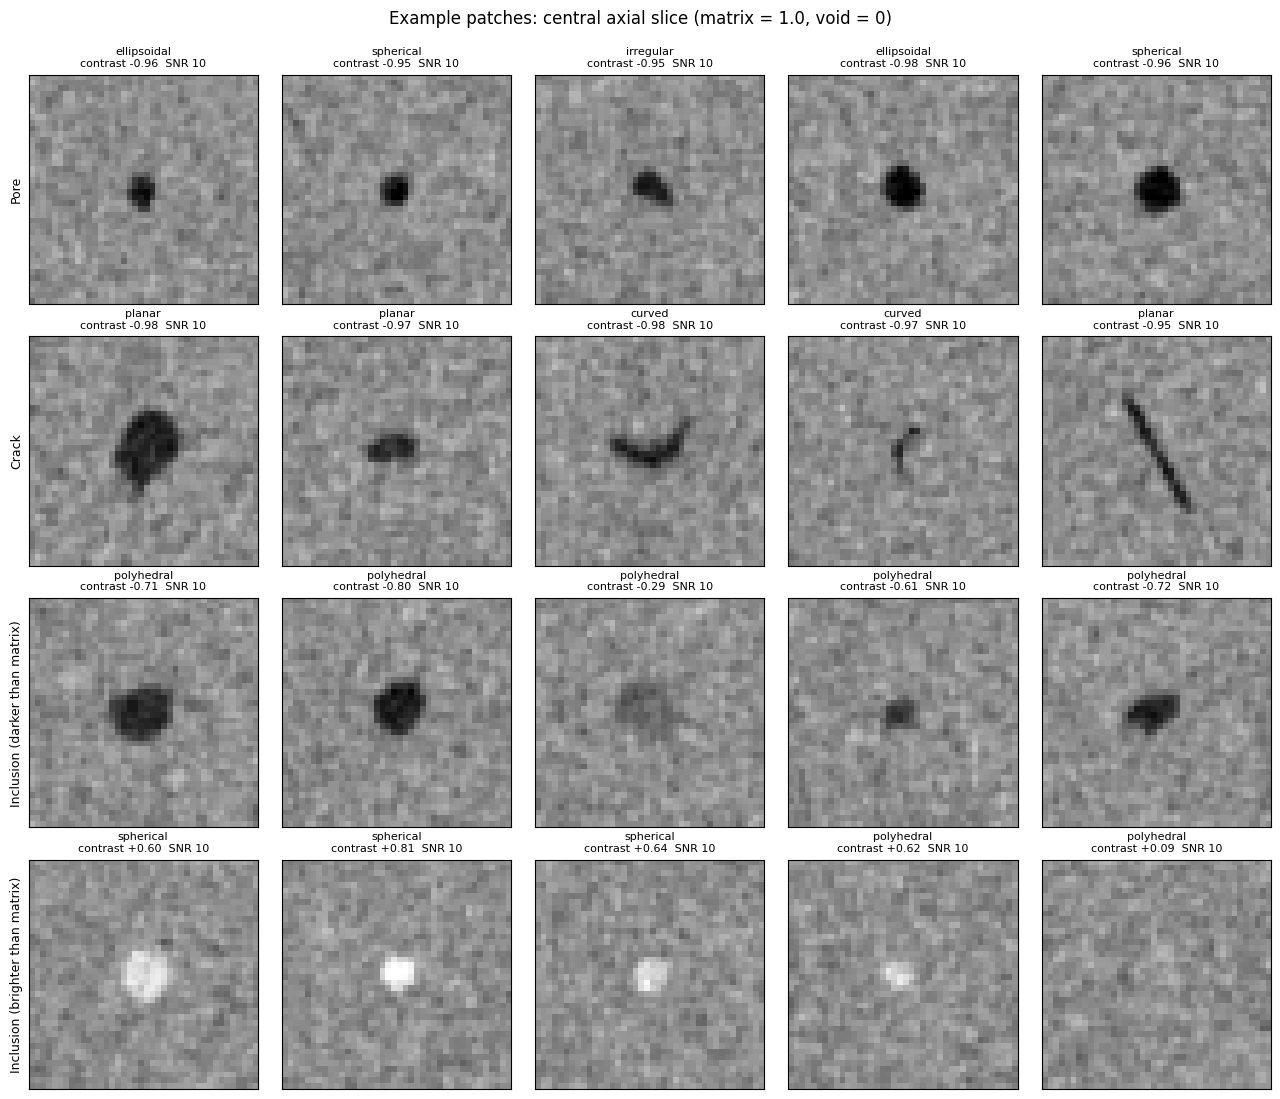

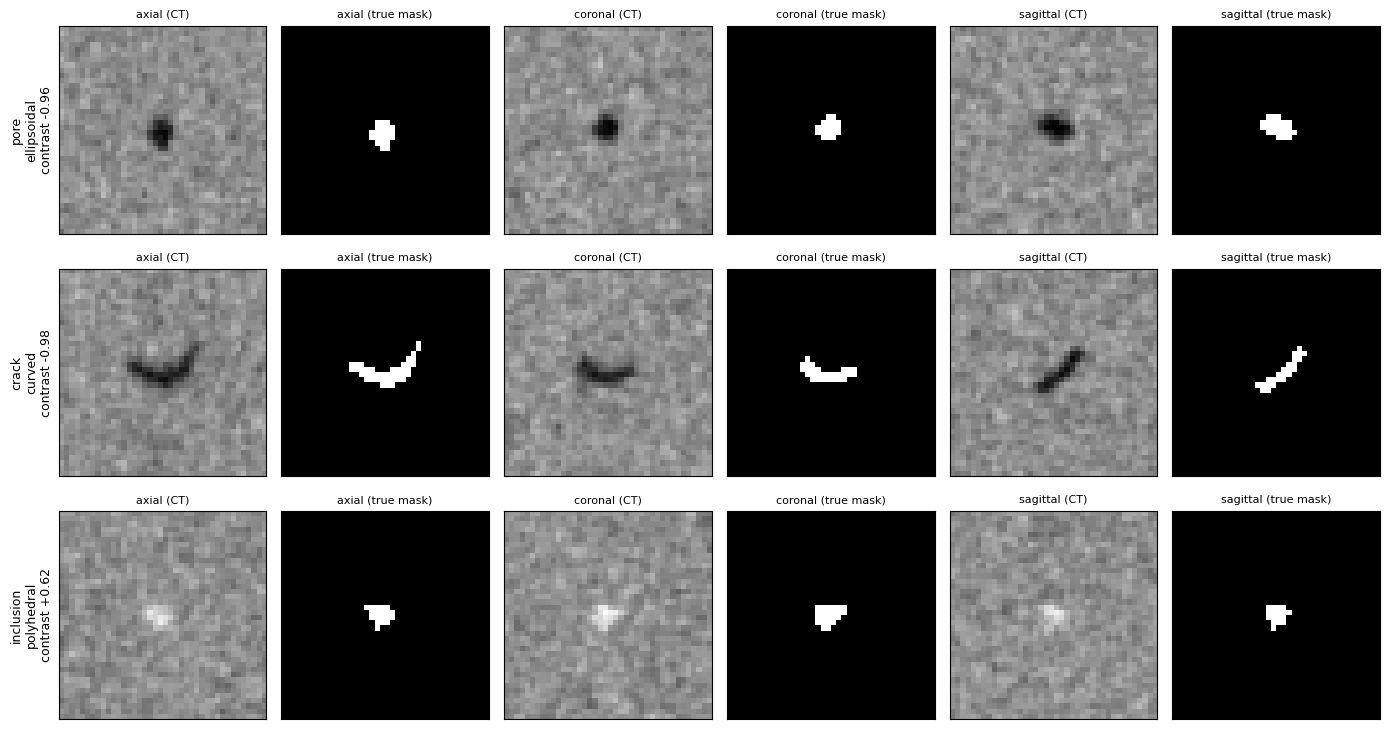

In [ ]:
def view(patch, bg):
    return patch.astype(np.float32) / bg

def plot_gallery(X, df, per_row=5, fname=None, seed=0):
    """4 rows: pore / crack / dark inclusion / bright inclusion. Central slice of each patch (matrix = 1.0)."""
    rng = np.random.default_rng(seed)
    groups = [('Pore', df.label == 0), ('Crack', df.label == 1),
              ('Inclusion (darker than matrix)', (df.label == 2) & (df.contrast < 0)),
              ('Inclusion (brighter than matrix)', (df.label == 2) & (df.contrast > 0))]
    fig, axes = plt.subplots(4, per_row, figsize=(2.6 * per_row, 11))
    for r, (title, cond) in enumerate(groups):
        idx = rng.choice(np.where(cond)[0], per_row, replace=False)
        for c, i in enumerate(idx):
            ax = axes[r, c]
            ax.imshow(view(X[i], df.bg_level.iloc[i])[STORE // 2], cmap='gray', vmin=0, vmax=1.8)
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f"{df.subtype.iloc[i]}\ncontrast {df.contrast.iloc[i]:+.2f}  SNR {df.snr_value.iloc[i]}", fontsize=8)
        axes[r, 0].set_ylabel(title, fontsize=9)
    plt.suptitle('Example patches: central axial slice (matrix = 1.0, void = 0)', y=0.995)
    plt.tight_layout()
    if fname: plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()

def plot_3planes(X, M, df, fname=None, seed=1):
    """One example per class, three orthogonal slices + the exact ground-truth mask."""
    rng = np.random.default_rng(seed)
    picks = [rng.choice(np.where(df.label == k)[0]) for k in range(3)]
    fig, axes = plt.subplots(3, 6, figsize=(14, 7.5))
    for r, i in enumerate(picks):
        p = view(X[i], df.bg_level.iloc[i]); m = M[i]; h = STORE // 2
        for c, (img, mk, name) in enumerate([(p[h], m[h], 'axial'), (p[:, h], m[:, h], 'coronal'), (p[:, :, h], m[:, :, h], 'sagittal')]):
            axes[r, 2 * c].imshow(img, cmap='gray', vmin=0, vmax=1.8); axes[r, 2 * c].set_title(f'{name} (CT)', fontsize=8)
            axes[r, 2 * c + 1].imshow(mk, cmap='gray'); axes[r, 2 * c + 1].set_title(f'{name} (true mask)', fontsize=8)
        axes[r, 0].set_ylabel(f"{CLASS_NAMES[df.label.iloc[i]]}\n{df.subtype.iloc[i]}\ncontrast {df.contrast.iloc[i]:+.2f}", fontsize=9)
        for a in axes[r]: a.set_xticks([]); a.set_yticks([])
    plt.tight_layout()
    if fname: plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()

_specs = make_specs(np.random.default_rng(SEED))
t0 = time.time()
_X, _M, _rows = build_parent(_specs[1])
_df = pd.DataFrame(_rows)
print(f'One parent volume built in {time.time()-t0:.1f} s  ->  {len(_df)} patches of shape {_X.shape[1:]}')
print(_df.groupby('class_name')[['actual_volume', 'abs_contrast']].mean().round(2))
plot_gallery(_X, _df, per_row=5)
plot_3planes(_X, _M, _df)

In [ ]:
SPLIT_N = {'train': 5250, 'val': 1125, 'test': 1125}
rng_main = np.random.default_rng(SEED)
specs = make_specs(rng_main)
assert len(specs) == N_PARENTS

Xs = {s: np.zeros((n, STORE, STORE, STORE), np.float16) for s, n in SPLIT_N.items()}
Ms = {s: np.zeros((n, STORE, STORE, STORE), np.uint8) for s, n in SPLIT_N.items()}
slot = {s: rng_main.permutation(n) for s, n in SPLIT_N.items()}
used = {s: 0 for s in SPLIT_N}
rows_by_split = {s: [None] * n for s, n in SPLIT_N.items()}

t0 = time.time()
for spec in tqdm(specs, desc='parent volumes'):
    X, M, rows = build_parent(spec)
    s, n = spec['split'], len(rows)
    pos = slot[s][used[s]: used[s] + n]; used[s] += n
    Xs[s][pos] = X; Ms[s][pos] = M
    for p, r in zip(pos, rows):
        rows_by_split[s][p] = r
print(f'Done in {(time.time()-t0)/60:.1f} min')
assert all(used[s] == SPLIT_N[s] for s in SPLIT_N), used

dfs = []
for s in SPLIT_N:
    d = pd.DataFrame(rows_by_split[s]); d.insert(0, 'row', np.arange(len(d)))
    d.insert(0, 'patch_id', [f'{s}_{i:05d}' for i in range(len(d))])
    dfs.append(d)
df_all = pd.concat(dfs, ignore_index=True)
print(df_all.shape)
df_all.head()

parent volumes:   0%|          | 0/200 [00:00<?, ?it/s]

Done in 4.3 min
(7500, 19)


,patch_id,row,label,class_name,subtype,parent_id,split,snr_tier,snr_value,matrix_level,psf_sigma,contrast,abs_contrast,contrast_bin,target_volume,actual_volume,fill_fraction,bg_level,foreign_voxels
0,train_00000,0,0,pore,spherical,185,train,low,10,1.0710,0.818,-0.9549,0.9549,void,520,520,0.008125,1.0694,0
1,train_00001,1,0,pore,irregular,124,train,high,40,0.9605,0.869,-0.9849,0.9849,void,165,165,0.002578,0.9594,0
2,train_00002,2,0,pore,spherical,199,train,high,40,1.1550,0.718,-0.9641,0.9641,void,123,123,0.001922,1.1559,0
3,train_00003,3,1,crack,curved,127,train,low,10,0.9588,0.682,-0.9690,0.9690,void,80,79,0.001234,0.9708,0
4,train_00004,4,1,crack,curved,99,train,high,40,1.0019,0.873,-0.9770,0.9770,void,114,114,0.001781,1.0000,0


In [ ]:
for s in SPLIT_N:
    np.save(f'{OUT_DIR}/patches_{s}.npy', Xs[s])
    np.save(f'{OUT_DIR}/masks_{s}.npy', Ms[s])
    df_all[df_all.split == s].to_csv(f'{OUT_DIR}/index_{s}.csv', index=False)
df_all.to_csv(f'{OUT_DIR}/index_all.csv', index=False)

config = dict(SEED=SEED, N_PARENTS=N_PARENTS, N_PER_CLASS=N_PER_CLASS, PARENT=PARENT, CELL=CELL, STORE=STORE,
              V_RANGE=V_RANGE, CONTRAST_RANGE=CONTRAST_RANGE, BIN_EDGES=BIN_EDGES, SNR_TIERS=SNR_TIERS,
              PSF_RANGE=PSF_RANGE, MATRIX_RANGE=MATRIX_RANGE, SUBTYPES={str(k): v for k, v in SUBTYPES.items()},
              CLASS_NAMES=CLASS_NAMES, SPLIT_N=SPLIT_N)
json.dump(config, open(f'{OUT_DIR}/data_config.json', 'w'), indent=2)
print('Saved to', OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    p = os.path.join(OUT_DIR, f)
    if os.path.isfile(p):
        print(f'  {f:24s} {os.path.getsize(p)/1e6:8.1f} MB')

Saved to /content/drive/MyDrive/defect_project/data
  data_config.json              0.0 MB
  index_all.csv                 0.8 MB
  index_test.csv                0.1 MB
  index_train.csv               0.6 MB
  index_val.csv                 0.1 MB
  masks_test.npy               72.0 MB
  masks_train.npy             336.0 MB
  masks_val.npy                72.0 MB
  patches_test.npy            144.0 MB
  patches_train.npy           672.0 MB
  patches_val.npy             144.0 MB


--- 1. Patches per split and class (brief: 5,250 / 1,125 / 1,125 ; 2,500 per class) ---
class_name  crack  inclusion  pore   All
split                                   
test          375        375   375  1125
train        1750       1750  1750  5250
val           375        375   375  1125
All          2500       2500  2500  7500

--- 2. Volume-disjoint check (no parent volume may appear in two splits) ---
{'train': 140, 'val': 30, 'test': 30} parents per split
OK: zero parent volumes shared between train / val / test

--- 3. Noise tiers per split (needed for the robustness experiment) ---
snr_tier  high   low  medium
split                       
test       375   372     378
train     1764  1725    1761
val        378   381     366

--- 4. Contrast bins of inclusions per split (needed for the contrast-stratified results) ---
contrast_bin  moderate  obvious  subtle
split                                  
test               142      179      54
train              652      786     312
v

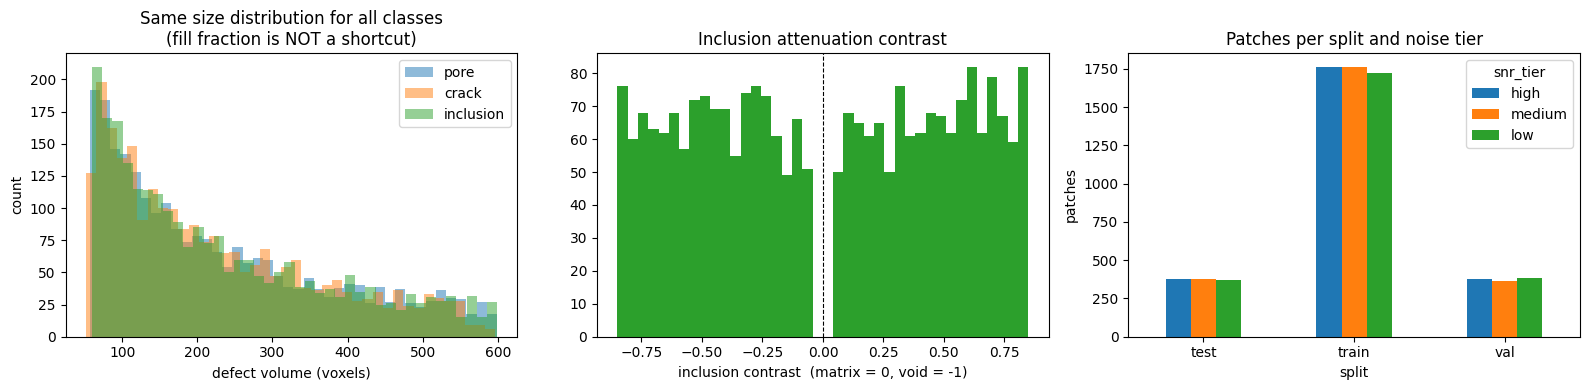

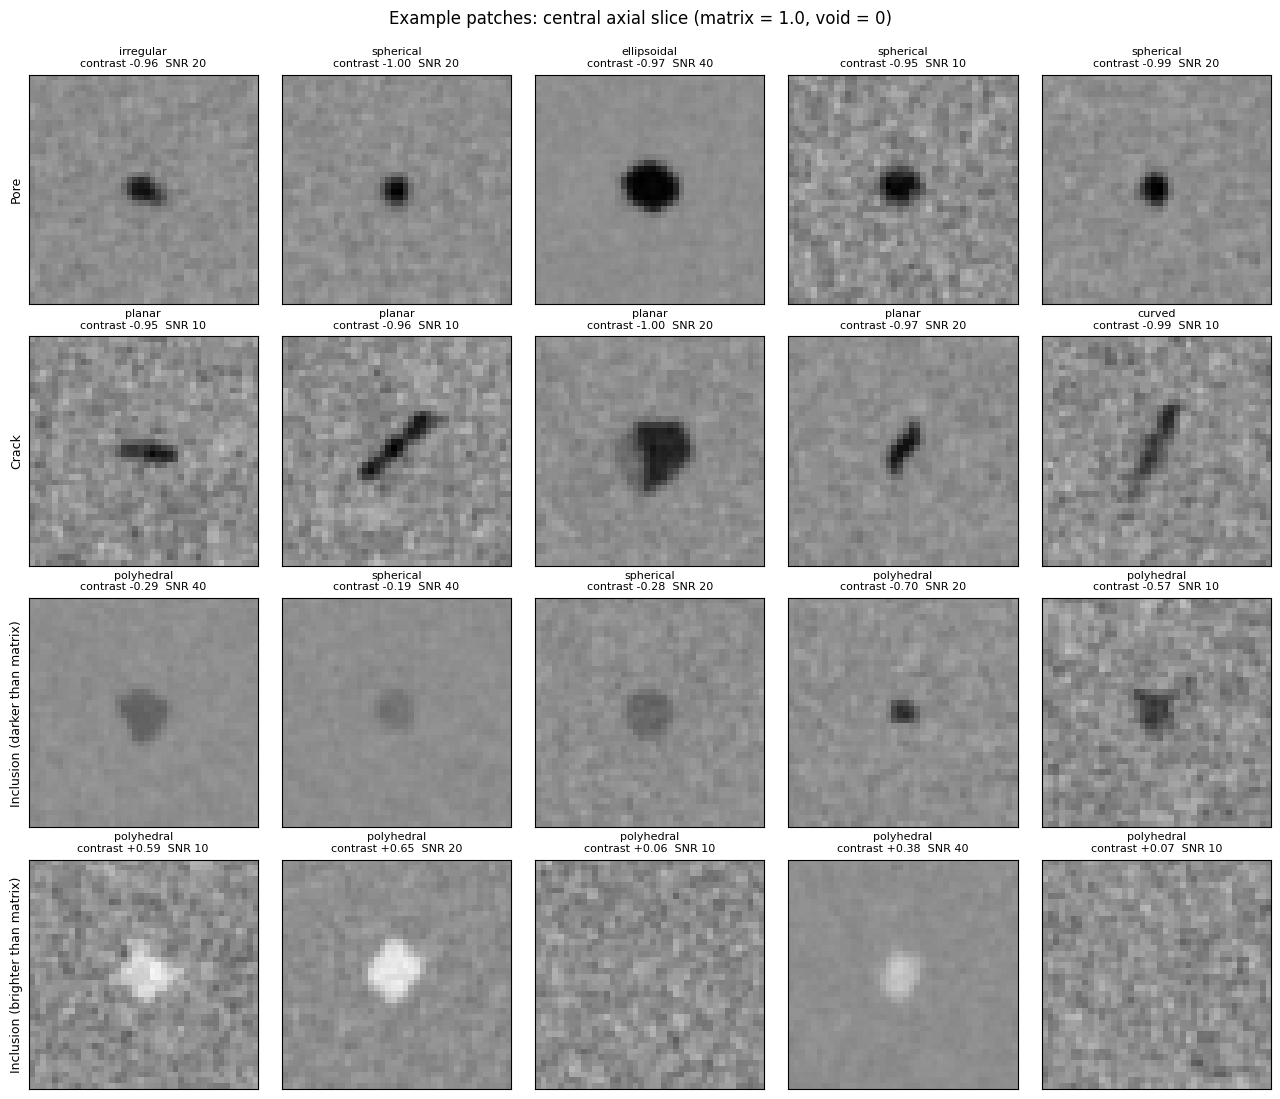

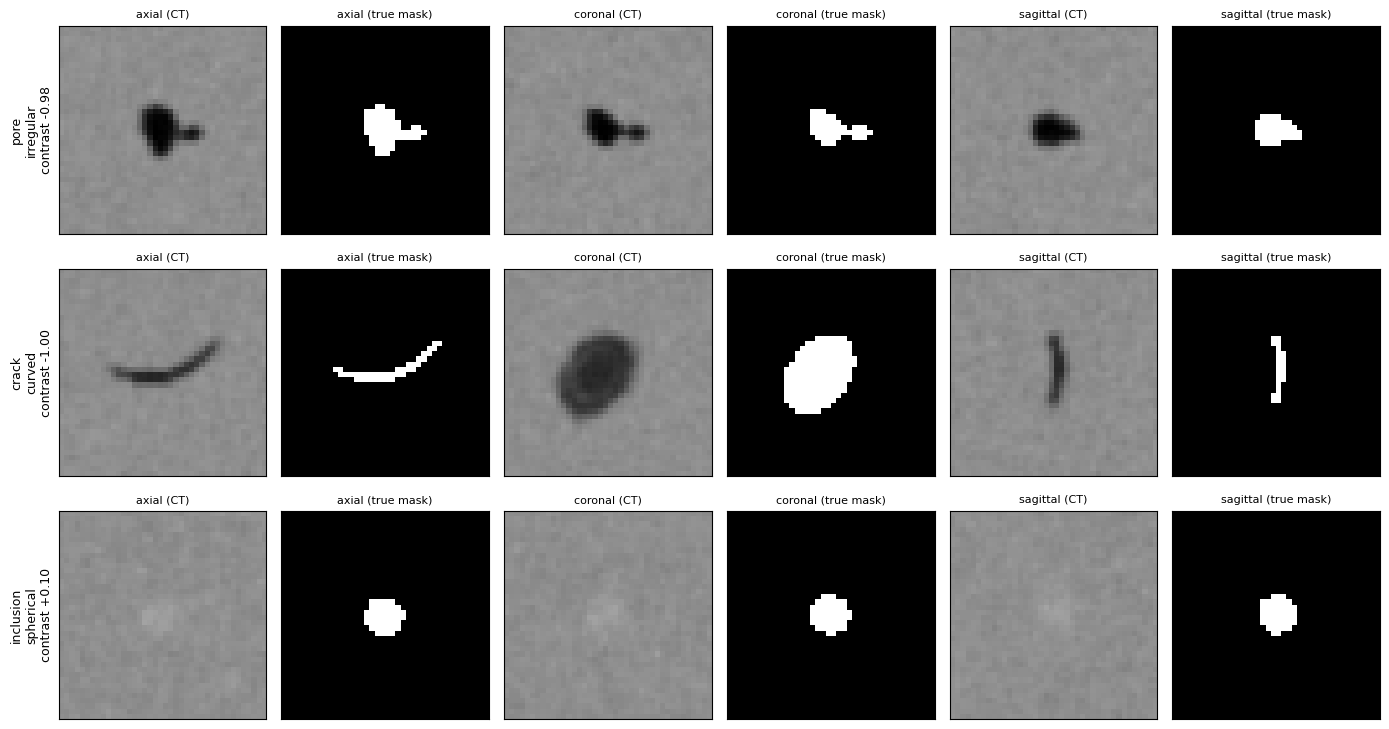

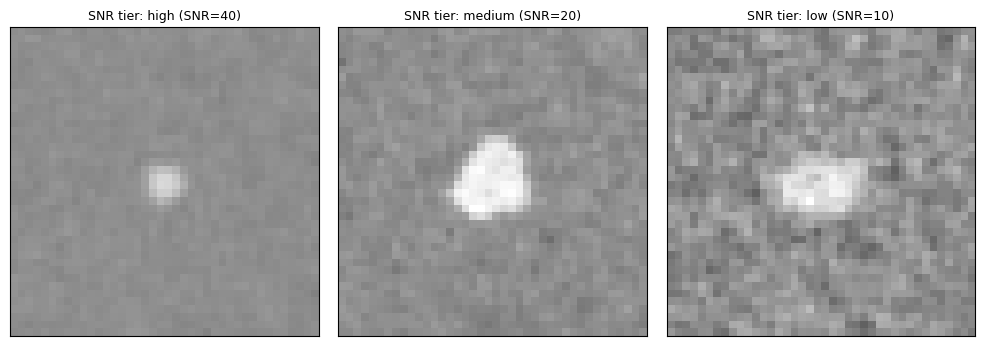


Reload check -> patches_test.npy (1125, 40, 40, 40) float16 | index_test.csv (1125, 19)
ALL CHECKS PASSED - data generation complete.


In [ ]:
print('--- 1. Patches per split and class (brief: 5,250 / 1,125 / 1,125 ; 2,500 per class) ---')
print(pd.crosstab(df_all.split, df_all.class_name, margins=True))

print('\n--- 2. Volume-disjoint check (no parent volume may appear in two splits) ---')
ids = {s: set(df_all[df_all.split == s].parent_id) for s in SPLIT_N}
print({s: len(v) for s, v in ids.items()}, 'parents per split')
assert not (ids['train'] & ids['val']) and not (ids['train'] & ids['test']) and not (ids['val'] & ids['test'])
print('OK: zero parent volumes shared between train / val / test')

print('\n--- 3. Noise tiers per split (needed for the robustness experiment) ---')
print(pd.crosstab(df_all.split, df_all.snr_tier))

print('\n--- 4. Contrast bins of inclusions per split (needed for the contrast-stratified results) ---')
print(pd.crosstab(df_all[df_all.label == 2].split, df_all[df_all.label == 2].contrast_bin))

print('\n--- 5. Is defect size a shortcut? (KS test on defect volume; p > 0.05 = distributions indistinguishable) ---')
v = {k: df_all[df_all.label == i].actual_volume.values for i, k in enumerate(CLASS_NAMES)}
for a, b in [('pore', 'crack'), ('pore', 'inclusion'), ('crack', 'inclusion')]:
    st, p = ks_2samp(v[a], v[b]); print(f'  {a:6s} vs {b:9s}: KS = {st:.3f}, p = {p:.3f}')
print('  median volume (voxels):', {k: int(np.median(x)) for k, x in v.items()})

print('\n--- 6. Contamination check: voxels of OTHER defects inside a patch ---')
print('  total foreign voxels =', int(df_all.foreign_voxels.sum()), '(should be 0)')

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, k in enumerate(CLASS_NAMES):
    ax[0].hist(v[k], bins=40, alpha=0.5, label=k)
ax[0].set_xlabel('defect volume (voxels)'); ax[0].set_ylabel('count'); ax[0].legend()
ax[0].set_title('Same size distribution for all classes\n(fill fraction is NOT a shortcut)')
inc = df_all[df_all.label == 2]
ax[1].hist(inc.contrast, bins=40, color='C2'); ax[1].axvline(0, color='k', ls='--', lw=0.8)
ax[1].set_xlabel('inclusion contrast  (matrix = 0, void = -1)'); ax[1].set_title('Inclusion attenuation contrast')
cnt = pd.crosstab(df_all.split, df_all.snr_tier)[list(SNR_TIERS)]
cnt.plot(kind='bar', ax=ax[2], rot=0); ax[2].set_title('Patches per split and noise tier'); ax[2].set_ylabel('patches')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/figures/data_overview.png', dpi=150); plt.show()

plot_gallery(Xs['train'], df_all[df_all.split == 'train'].reset_index(drop=True), per_row=5,
             fname=f'{OUT_DIR}/figures/gallery_classes.png', seed=3)
plot_3planes(Xs['train'], Ms['train'], df_all[df_all.split == 'train'].reset_index(drop=True),
             fname=f'{OUT_DIR}/figures/three_planes.png', seed=5)

fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
d_tr = df_all[df_all.split == 'train'].reset_index(drop=True)
for a, tier in zip(ax, SNR_TIERS):
    i = d_tr[(d_tr.label == 2) & (d_tr.snr_tier == tier) & (d_tr.contrast > 0.4)].index[0]
    a.imshow(view(Xs['train'][i], d_tr.bg_level[i])[STORE // 2], cmap='gray', vmin=0, vmax=1.8)
    a.set_title(f'SNR tier: {tier} (SNR={SNR_TIERS[tier]})', fontsize=9); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/figures/noise_tiers.png', dpi=150); plt.show()

chk = np.load(f'{OUT_DIR}/patches_test.npy', mmap_mode='r'); idx = pd.read_csv(f'{OUT_DIR}/index_test.csv')
print('\nReload check -> patches_test.npy', chk.shape, chk.dtype, '| index_test.csv', idx.shape)
assert chk.shape[0] == len(idx) == SPLIT_N['test']
print('ALL CHECKS PASSED - data generation complete.')

In [ ]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
warnings.filterwarnings('ignore')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/defect_project'
except ImportError:
    BASE = './defect_project'
DATA_DIR, MODEL_DIR, RES_DIR = BASE + '/data', BASE + '/models', BASE + '/results'
FIG_DIR = RES_DIR + '/figures'
for d in (MODEL_DIR, RES_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

SEED, CROP, BATCH = 42, 32, 64
MAX_EPOCHS, PATIENCE, LR = 60, 12, 1e-3
FORCE_RETRAIN = False
CLASS_NAMES = ['pore', 'crack', 'inclusion']

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device, '|', torch.cuda.get_device_name(0) if device == 'cuda' else 'NO GPU!')
if device != 'cuda':
    print('>>> Turn on the GPU: Runtime -> Change runtime type -> T4 GPU, then re-run from Cell 1.')
torch.manual_seed(SEED); np.random.seed(SEED)
torch.backends.cudnn.benchmark = True
print('Data folder  :', DATA_DIR)
print('Results folder:', RES_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda | Tesla T4
Data folder  : /content/drive/MyDrive/defect_project/data
Results folder: /content/drive/MyDrive/defect_project/results


train: patches (5250, 40, 40, 40), masks (5250, 40, 40, 40), labels [1750 1750 1750]
val  : patches (1125, 40, 40, 40), masks (1125, 40, 40, 40), labels [375 375 375]
test : patches (1125, 40, 40, 40), masks (1125, 40, 40, 40), labels [375 375 375]
Normalised background (outer shell): mean = 0.0001  (should be ~0)


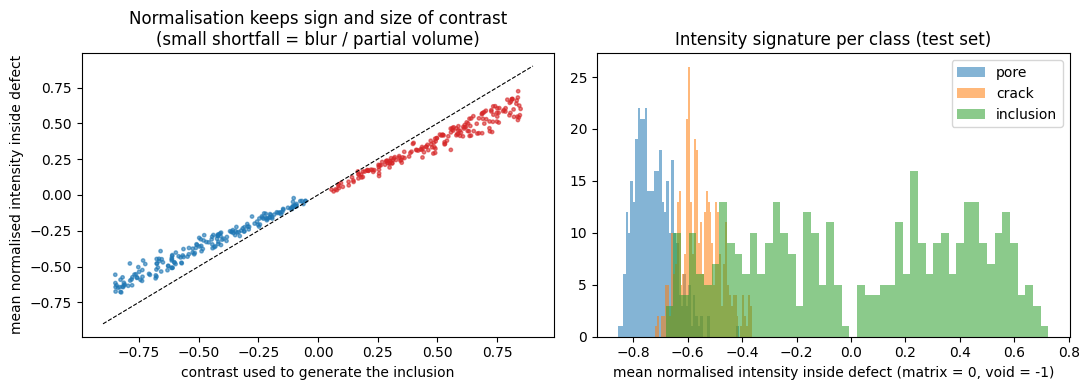

In [ ]:
def load_split(s):
    X = np.load(f'{DATA_DIR}/patches_{s}.npy')
    M = np.load(f'{DATA_DIR}/masks_{s}.npy')
    df = pd.read_csv(f'{DATA_DIR}/index_{s}.csv')
    assert len(X) == len(M) == len(df)
    return X, M, df

def normalise(X, bg, chunk=500):
    out = np.empty(X.shape, np.float16)
    for k in range(0, len(X), chunk):
        b = bg[k:k + chunk].astype(np.float32)[:, None, None, None]
        out[k:k + chunk] = ((X[k:k + chunk].astype(np.float32) - b) / b).astype(np.float16)
    return out

RAW = {}
for s in ['train', 'val', 'test']:
    X, M, df = load_split(s)
    RAW[s] = dict(x=normalise(X, df.bg_level.values), m=M, df=df)
    del X
    print(f'{s:5s}: patches {RAW[s]["x"].shape}, masks {RAW[s]["m"].shape}, labels {np.bincount(df.label)}')

def mean_in_mask(X, M, chunk=250):
    out = []
    for k in range(0, len(X), chunk):
        x, m = X[k:k + chunk].astype(np.float32), M[k:k + chunk].astype(np.float32)
        out.append((x * m).sum((1, 2, 3)) / m.sum((1, 2, 3)))
    return np.concatenate(out)

dft = RAW['test']['df']
mm = mean_in_mask(RAW['test']['x'], RAW['test']['m'])
shell = np.ones((40, 40, 40), bool); shell[4:-4, 4:-4, 4:-4] = False
print('Normalised background (outer shell): mean = %.4f  (should be ~0)' % RAW['test']['x'][:200][:, shell].astype(np.float32).mean())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
inc = (dft.label == 2).values
ax[0].scatter(dft.contrast[inc], mm[inc], s=6, c=np.where(dft.contrast[inc] > 0, 'tab:red', 'tab:blue'), alpha=0.6)
ax[0].plot([-0.9, 0.9], [-0.9, 0.9], 'k--', lw=0.8)
ax[0].set_xlabel('contrast used to generate the inclusion'); ax[0].set_ylabel('mean normalised intensity inside defect')
ax[0].set_title('Normalisation keeps sign and size of contrast\n(small shortfall = blur / partial volume)')
for k, n in enumerate(CLASS_NAMES):
    ax[1].hist(mm[(dft.label == k).values], bins=50, alpha=0.55, label=n)
ax[1].set_xlabel('mean normalised intensity inside defect (matrix = 0, void = -1)'); ax[1].legend()
ax[1].set_title('Intensity signature per class (test set)')
plt.tight_layout(); plt.savefig(FIG_DIR + '/preprocessing_check.png', dpi=150); plt.show()

In [ ]:
DATA = {}
for s in RAW:
    DATA[s] = dict(x_raw=torch.from_numpy(RAW[s]['x']).to(device),
                   x_mask=torch.from_numpy(RAW[s]['m']).to(device),
                   y=torch.tensor(RAW[s]['df'].label.values, dtype=torch.long, device=device),
                   df=RAW[s]['df'])
if device == 'cuda':
    print(f'GPU memory used: {torch.cuda.memory_allocated()/1e9:.2f} GB')

GPU memory used: 1.44 GB


In [ ]:
def conv_block(cin, cout):
    return nn.Sequential(
        nn.Conv3d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm3d(cout), nn.ReLU(inplace=True),
        nn.Conv3d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm3d(cout), nn.ReLU(inplace=True),
        nn.MaxPool3d(2))

class DefectCNN3D(nn.Module):
    def __init__(self, n_classes=3, ch=(16, 32, 64, 128), drop=0.3):
        super().__init__()
        c = (1,) + tuple(ch)
        self.features = nn.Sequential(*[conv_block(c[i], c[i + 1]) for i in range(4)])
        self.head = nn.Sequential(nn.Linear(ch[-1], 32), nn.ReLU(inplace=True), nn.Dropout(drop), nn.Linear(32, n_classes))
    def forward(self, x):
        x = self.features(x)
        x = x.mean(dim=(2, 3, 4))
        return self.head(x)

_m = DefectCNN3D()
n_params = sum(p.numel() for p in _m.parameters())
print(f'DefectCNN3D parameters: {n_params:,}  (brief: ~0.5-1 M)')
del _m

DefectCNN3D parameters: 883,443  (brief: ~0.5-1 M)


In [ ]:
def center_crop(x):
    o = (x.shape[-1] - CROP) // 2
    return x[:, o:o + CROP, o:o + CROP, o:o + CROP].unsqueeze(1).float()

def augment(x, intensity=False):
    B, S = x.shape[0], x.shape[-1]
    out = torch.empty((B, 1, CROP, CROP, CROP), device=x.device, dtype=torch.float32)
    offs = torch.randint(0, S - CROP + 1, (B, 3)).tolist()
    for i in range(B):
        a, b, c = offs[i]
        v = x[i, a:a + CROP, b:b + CROP, c:c + CROP].float()
        v = v.permute(*torch.randperm(3).tolist())
        flips = [d for d in range(3) if torch.rand(1).item() < 0.5]
        if flips:
            v = torch.flip(v, flips)
        out[i, 0] = v
    if intensity:
        shp = (B, 1, 1, 1, 1)
        gain = torch.empty(shp, device=x.device).uniform_(0.95, 1.05)
        offset = torch.empty(shp, device=x.device).uniform_(-0.02, 0.02)
        extra = torch.empty(shp, device=x.device).uniform_(0.0, 0.02)
        out = out * gain + offset + torch.randn_like(out) * extra
    return out

def make_scaler():
    try:
        return torch.amp.GradScaler('cuda')
    except Exception:
        return torch.cuda.amp.GradScaler()

def train_one_epoch(model, opt, scaler, X, y, intensity):
    model.train()
    n = X.shape[0]
    perm = torch.randperm(n, device=X.device)
    loss_sum = torch.zeros((), device=X.device); correct = torch.zeros((), device=X.device); seen = 0
    for k in range(0, n - BATCH + 1, BATCH):
        idx = perm[k:k + BATCH]
        xb, yb = augment(X[idx], intensity), y[idx]
        opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda', dtype=torch.float16):
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        loss_sum += loss.detach() * len(idx)
        correct += (logits.argmax(1) == yb).sum()
        seen += len(idx)
    return loss_sum.item() / seen, correct.item() / seen

@torch.no_grad()
def predict(model, X, bs=256):
    model.eval()
    out = []
    for k in range(0, X.shape[0], bs):
        with torch.autocast('cuda', dtype=torch.float16):
            out.append(model(center_crop(X[k:k + bs])).float())
    return torch.cat(out)

def train_model(name, Xtr, ytr, Xva, yva, intensity_aug, max_epochs=MAX_EPOCHS, patience=PATIENCE):
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = DefectCNN3D().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=4)
    scaler = make_scaler()
    last, best = f'{MODEL_DIR}/{name}_last.pt', f'{MODEL_DIR}/{name}_best.pt'
    hist, start, best_f1, bad = [], 0, -1.0, 0
    if os.path.exists(last) and not FORCE_RETRAIN:
        ck = torch.load(last, map_location=device, weights_only=False)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
        hist, start, best_f1, bad = ck['hist'], ck['epoch'], ck['best_f1'], ck['bad']
        print(f'[{name}] resuming from epoch {start} (best val macro-F1 so far {best_f1:.4f})')
    yva_np = yva.cpu().numpy()
    finished = (bad >= patience) or (start >= max_epochs)
    for ep in range(start, 0 if finished else max_epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, opt, scaler, Xtr, ytr, intensity_aug)
        logits = predict(model, Xva)
        val_loss = F.cross_entropy(logits, yva).item()
        pred = logits.argmax(1).cpu().numpy()
        f1, acc = f1_score(yva_np, pred, average='macro'), accuracy_score(yva_np, pred)
        sched.step(f1)
        if f1 > best_f1 + 1e-4:
            best_f1, bad = f1, 0
            torch.save(model.state_dict(), best)
        else:
            bad += 1
        hist.append(dict(epoch=ep + 1, train_loss=tr_loss, train_acc=tr_acc, val_loss=val_loss, val_acc=acc,
                         val_macro_f1=f1, lr=opt.param_groups[0]['lr'], seconds=time.time() - t0))
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        hist=hist, epoch=ep + 1, best_f1=best_f1, bad=bad), last)
        print(f'[{name}] ep {ep+1:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {val_loss:.3f} acc {acc:.3f} '
              f'macro-F1 {f1:.3f} | best {best_f1:.3f} | lr {opt.param_groups[0]["lr"]:.0e} | {time.time()-t0:.0f}s')
        if bad >= patience:
            print(f'[{name}] early stopping')
            break
    pd.DataFrame(hist).to_csv(f'{RES_DIR}/history_{name}.csv', index=False)
    model.load_state_dict(torch.load(best, map_location=device, weights_only=False))
    return model, pd.DataFrame(hist)
print('Training functions ready')

Training functions ready


In [ ]:
assert device == 'cuda', 'Switch the runtime to a T4 GPU first'
m = DefectCNN3D().to(device)
xb = augment(DATA['train']['x_raw'][:8], intensity=True)
print('augmented batch :', tuple(xb.shape), xb.dtype, '| value range %.2f .. %.2f' % (xb.min().item(), xb.max().item()))
xm = augment(DATA['train']['x_mask'][:8], intensity=False)
print('mask batch      :', tuple(xm.shape), '| unique values', torch.unique(xm).tolist())
t0 = time.time()
opt = torch.optim.Adam(m.parameters(), lr=LR); sc = make_scaler()
loss, acc = train_one_epoch(m, opt, sc, DATA['train']['x_raw'][:640], DATA['train']['y'][:640], True)
print(f'1 mini-epoch (640 patches): loss {loss:.3f}, acc {acc:.3f}, {time.time()-t0:.1f}s')
lg = predict(m, DATA['val']['x_raw'][:300])
print('predict output  :', tuple(lg.shape))
est = (time.time() - t0) * (5250 / 640)
print(f'Estimated time per full epoch: ~{est:.0f} s  ->  worst case {MAX_EPOCHS} epochs = ~{est*MAX_EPOCHS/60:.0f} min per model')
del m, opt, sc
print('SMOKE TEST PASSED - safe to start training')

augmented batch : (8, 1, 32, 32, 32) torch.float32 | value range -1.22 .. 0.40
mask batch      : (8, 1, 32, 32, 32) | unique values [0.0, 1.0]
1 mini-epoch (640 patches): loss 0.839, acc 0.603, 10.3s
predict output  : (300, 3)
Estimated time per full epoch: ~94 s  ->  worst case 60 epochs = ~94 min per model
SMOKE TEST PASSED - safe to start training


In [ ]:
model_raw, hist_raw = train_model('cnn_raw', DATA['train']['x_raw'], DATA['train']['y'],
                                  DATA['val']['x_raw'], DATA['val']['y'], intensity_aug=True)
print('\nBest validation macro-F1 (raw CNN): %.4f' % hist_raw.val_macro_f1.max())

[cnn_raw] ep  1 | train loss 0.436 acc 0.830 | val loss 0.219 acc 0.924 macro-F1 0.922 | best 0.922 | lr 1e-03 | 6s
[cnn_raw] ep  2 | train loss 0.183 acc 0.936 | val loss 0.293 acc 0.904 macro-F1 0.902 | best 0.922 | lr 1e-03 | 5s
[cnn_raw] ep  3 | train loss 0.138 acc 0.955 | val loss 0.363 acc 0.871 macro-F1 0.867 | best 0.922 | lr 1e-03 | 5s
[cnn_raw] ep  4 | train loss 0.110 acc 0.966 | val loss 0.353 acc 0.906 macro-F1 0.905 | best 0.922 | lr 1e-03 | 5s
[cnn_raw] ep  5 | train loss 0.110 acc 0.963 | val loss 0.114 acc 0.962 macro-F1 0.962 | best 0.962 | lr 1e-03 | 5s
[cnn_raw] ep  6 | train loss 0.095 acc 0.972 | val loss 0.242 acc 0.913 macro-F1 0.912 | best 0.962 | lr 1e-03 | 5s
[cnn_raw] ep  7 | train loss 0.078 acc 0.974 | val loss 0.310 acc 0.907 macro-F1 0.907 | best 0.962 | lr 1e-03 | 5s
[cnn_raw] ep  8 | train loss 0.099 acc 0.966 | val loss 0.211 acc 0.935 macro-F1 0.934 | best 0.962 | lr 1e-03 | 5s
[cnn_raw] ep  9 | train loss 0.094 acc 0.969 | val loss 0.296 acc 0.934 

In [ ]:
model_shape, hist_shape = train_model('cnn_shape_only', DATA['train']['x_mask'], DATA['train']['y'],
                                      DATA['val']['x_mask'], DATA['val']['y'], intensity_aug=False)
print('\nBest validation macro-F1 (shape-only CNN): %.4f' % hist_shape.val_macro_f1.max())

[cnn_shape_only] ep  1 | train loss 0.593 acc 0.648 | val loss 0.508 acc 0.698 macro-F1 0.682 | best 0.682 | lr 1e-03 | 5s
[cnn_shape_only] ep  2 | train loss 0.526 acc 0.648 | val loss 0.489 acc 0.686 macro-F1 0.674 | best 0.682 | lr 1e-03 | 5s
[cnn_shape_only] ep  3 | train loss 0.517 acc 0.665 | val loss 1.236 acc 0.491 macro-F1 0.432 | best 0.682 | lr 1e-03 | 5s
[cnn_shape_only] ep  4 | train loss 0.499 acc 0.664 | val loss 0.481 acc 0.665 macro-F1 0.557 | best 0.682 | lr 1e-03 | 5s
[cnn_shape_only] ep  5 | train loss 0.498 acc 0.671 | val loss 0.536 acc 0.637 macro-F1 0.556 | best 0.682 | lr 1e-03 | 5s
[cnn_shape_only] ep  6 | train loss 0.492 acc 0.665 | val loss 0.483 acc 0.663 macro-F1 0.609 | best 0.682 | lr 5e-04 | 5s
[cnn_shape_only] ep  7 | train loss 0.487 acc 0.683 | val loss 0.472 acc 0.717 macro-F1 0.714 | best 0.714 | lr 5e-04 | 5s
[cnn_shape_only] ep  8 | train loss 0.485 acc 0.695 | val loss 0.477 acc 0.684 macro-F1 0.652 | best 0.714 | lr 5e-04 | 5s
[cnn_shape_only]

 Raw-intensity CNN - per-class results on the TEST set
              precision    recall  f1-score   support

        pore      0.976     0.995     0.985       375
       crack      0.995     0.992     0.993       375
   inclusion      1.000     0.984     0.992       375

    accuracy                          0.990      1125
   macro avg      0.990     0.990     0.990      1125
weighted avg      0.990     0.990     0.990      1125

 Shape-only CNN (ablation) - per-class results on the TEST set
              precision    recall  f1-score   support

        pore      0.669     0.883     0.761       375
       crack      0.997     1.000     0.999       375
   inclusion      0.831     0.563     0.671       375

    accuracy                          0.815      1125
   macro avg      0.832     0.815     0.810      1125
weighted avg      0.832     0.815     0.810      1125



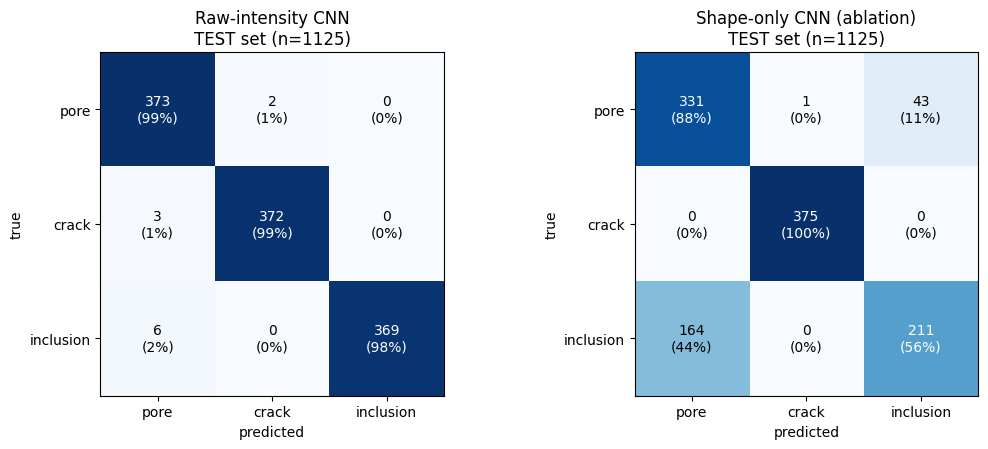

                    model  test_accuracy  test_macro_f1  val_accuracy  val_macro_f1
        Raw-intensity CNN         0.9902         0.9902        0.9964        0.9964
Shape-only CNN (ablation)         0.8151         0.8102        0.8276        0.8238


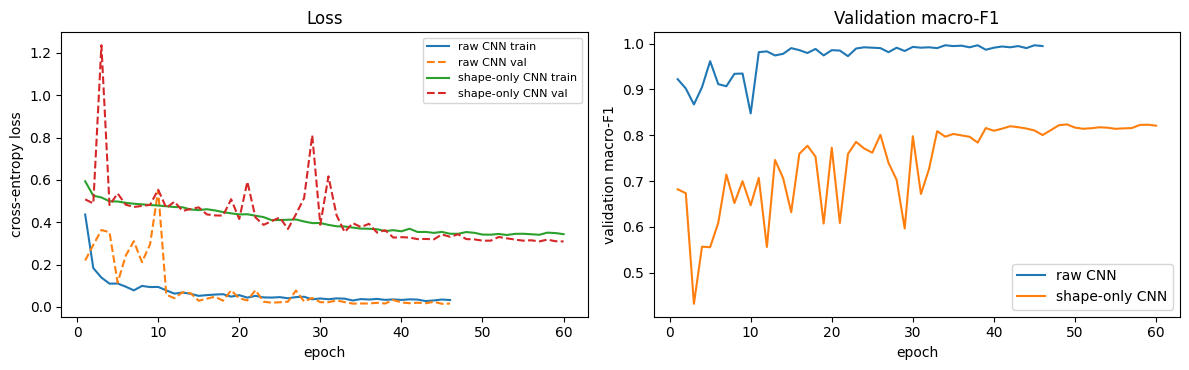

Saved: weights -> /content/drive/MyDrive/defect_project/models | predictions + tables + figures -> /content/drive/MyDrive/defect_project/results


In [ ]:
def save_preds(name, model, key):
    res = {}
    for s in ['val', 'test']:
        probs = torch.softmax(predict(model, DATA[s][key]), 1).cpu().numpy()
        d = DATA[s]['df']
        out = pd.DataFrame(dict(patch_id=d.patch_id, y_true=d.label.values, y_pred=probs.argmax(1),
                                p_pore=probs[:, 0], p_crack=probs[:, 1], p_inclusion=probs[:, 2]))
        out.to_csv(f'{RES_DIR}/preds_{name}_{s}.csv', index=False)
        res[s] = out
    return res

P = {'cnn_raw': save_preds('cnn_raw', model_raw, 'x_raw'),
     'cnn_shape_only': save_preds('cnn_shape_only', model_shape, 'x_mask')}

def plot_cm(ax, y, p, title):
    cm = confusion_matrix(y, p, labels=[0, 1, 2]); cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{cm[i, j]}\n({cmn[i, j]*100:.0f}%)', ha='center', va='center',
                    color='white' if cmn[i, j] > 0.5 else 'black', fontsize=10)
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(title)

rows = []
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a, (name, title) in zip(ax, [('cnn_raw', 'Raw-intensity CNN'), ('cnn_shape_only', 'Shape-only CNN (ablation)')]):
    t = P[name]['test']
    plot_cm(a, t.y_true, t.y_pred, f'{title}\nTEST set (n={len(t)})')
    rows.append(dict(model=title, test_accuracy=accuracy_score(t.y_true, t.y_pred),
                     test_macro_f1=f1_score(t.y_true, t.y_pred, average='macro'),
                     val_accuracy=accuracy_score(P[name]['val'].y_true, P[name]['val'].y_pred),
                     val_macro_f1=f1_score(P[name]['val'].y_true, P[name]['val'].y_pred, average='macro')))
    print('=' * 60, '\n', title, '- per-class results on the TEST set')
    print(classification_report(t.y_true, t.y_pred, target_names=CLASS_NAMES, digits=3))
plt.tight_layout(); plt.savefig(FIG_DIR + '/confusion_matrices_main.png', dpi=150); plt.show()

summary = pd.DataFrame(rows).round(4)
summary.to_csv(RES_DIR + '/summary_block2.csv', index=False)
print(summary.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for h, lab in [(hist_raw, 'raw CNN'), (hist_shape, 'shape-only CNN')]:
    ax[0].plot(h.epoch, h.train_loss, label=lab + ' train'); ax[0].plot(h.epoch, h.val_loss, '--', label=lab + ' val')
    ax[1].plot(h.epoch, h.val_macro_f1, label=lab)
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('cross-entropy loss'); ax[0].legend(fontsize=8); ax[0].set_title('Loss')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('validation macro-F1'); ax[1].legend(); ax[1].set_title('Validation macro-F1')
plt.tight_layout(); plt.savefig(FIG_DIR + '/training_curves.png', dpi=150); plt.show()
print('Saved: weights ->', MODEL_DIR, '| predictions + tables + figures ->', RES_DIR)

In [ ]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy.spatial import ConvexHull
from scipy.stats import skew, binomtest, chi2 as chi2_dist
from skimage import measure
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, precision_recall_fscore_support, classification_report
warnings.filterwarnings('ignore')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/defect_project'
except ImportError:
    BASE = './defect_project'
DATA_DIR, RES_DIR = BASE + '/data', BASE + '/results'
FIG_DIR, TAB_DIR = RES_DIR + '/figures', RES_DIR + '/tables'
for d in (FIG_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)

SEED = 42
CLASS_NAMES = ['pore', 'crack', 'inclusion']
DF = {s: pd.read_csv(f'{DATA_DIR}/index_{s}.csv') for s in ['train', 'val', 'test']}
for s in DF:
    print(f'{s:5s}: {len(DF[s])} patches from {DF[s].parent_id.nunique()} parent volumes')

needed = ['preds_cnn_raw_test.csv', 'preds_cnn_shape_only_test.csv', 'preds_cnn_raw_val.csv', 'preds_cnn_shape_only_val.csv']
missing = [f for f in needed if not os.path.exists(f'{RES_DIR}/{f}')]
assert not missing, f'Run Block 2 first - missing: {missing}'
print('Block 2 prediction files found.')

Mounted at /content/drive
train: 5250 patches from 140 parent volumes
val  : 1125 patches from 30 parent volumes
test : 1125 patches from 30 parent volumes
Block 2 prediction files found.


In [ ]:
CORNERS = np.array([[i, j, k] for i in (-.5, .5) for j in (-.5, .5) for k in (-.5, .5)], np.float32)
SHAPE_FEATS = ['volume', 'sphericity', 'solidity', 'bbox_fill', 'aspect_b_a', 'aspect_c_a', 'flatness_c_b', 'max_extent']
INT_FEATS = ['mean_in', 'std_in', 'skew_in', 'mean_ring', 'mean_patch', 'std_patch', 'skew_patch']
STRUCT26 = ndi.generate_binary_structure(3, 3)
SHELL = np.ones((40, 40, 40), bool); SHELL[4:-4, 4:-4, 4:-4] = False
_g = np.arange(40) - 19.5
DIST_C = np.sqrt(_g[:, None, None] ** 2 + _g[None, :, None] ** 2 + _g[None, None, :] ** 2)

def safe_skew(v):
    return 0.0 if (len(v) < 3 or np.std(v) < 1e-8) else float(skew(v))

def nearest_blob(cand):
    lab, n = ndi.label(cand, structure=STRUCT26)
    if n == 0:
        return None
    idx = np.arange(1, n + 1)
    size, mind = ndi.sum(cand, lab, idx), ndi.minimum(DIST_C, lab, idx)
    ok = np.where(size >= 5)[0]
    return None if len(ok) == 0 else (lab == idx[ok[np.argmin(mind[ok])]])

def threshold_mask(x):
    s = ndi.gaussian_filter(x, 0.7)
    bgv = s[SHELL]
    noise = 1.4826 * np.median(np.abs(bgv - np.median(bgv)))
    cand = np.abs(s) > max(4 * noise, 0.05)
    cand[SHELL] = False
    comp = nearest_blob(cand)
    if comp is not None:
        peak = np.percentile(np.abs(s[comp]), 95)
        ref = nearest_blob(comp & (np.abs(s) > 0.5 * peak))
        return ref if ref is not None else comp
    fallback = np.zeros((40, 40, 40), bool); fallback[18:22, 18:22, 18:22] = True
    return fallback

def shape_features(m):
    coords = np.argwhere(m).astype(np.float32)
    V = len(coords)
    ev = np.sort(np.linalg.eigvalsh(np.cov(coords.T) + np.eye(3) / 12.0))[::-1]
    a, b, c = np.sqrt(ev)
    ext = coords.max(0) - coords.min(0) + 1
    try:
        verts, faces, _, _ = measure.marching_cubes(np.pad(m, 1).astype(np.float32), 0.5)
        sph = (np.pi ** (1 / 3)) * (6 * V) ** (2 / 3) / measure.mesh_surface_area(verts, faces)
    except Exception:
        sph = np.nan
    try:
        sol = V / ConvexHull((coords[:, None, :] + CORNERS[None]).reshape(-1, 3)).volume
    except Exception:
        sol = np.nan
    return [V, sph, sol, V / ext.prod(), b / a, c / a, c / b, ext.max()]

def intensity_features(x, m):
    xin = x[m]
    ring = ndi.binary_dilation(m, iterations=3) & ~ndi.binary_dilation(m, iterations=1)
    cc = x[4:36, 4:36, 4:36].ravel()
    return [xin.mean(), xin.std(), safe_skew(xin), x[ring].mean() if ring.any() else 0.0, cc.mean(), cc.std(), safe_skew(cc)]

def feature_table(split, source='true'):
    X = np.load(f'{DATA_DIR}/patches_{split}.npy', mmap_mode='r')
    M = np.load(f'{DATA_DIR}/masks_{split}.npy', mmap_mode='r')
    bg = DF[split].bg_level.values
    rows, dice = [], []
    for i in range(len(bg)):
        x = (X[i].astype(np.float32) - bg[i]) / bg[i]
        mt = M[i].astype(bool)
        m = mt if source == 'true' else threshold_mask(x)
        dice.append(2 * (m & mt).sum() / (m.sum() + mt.sum()))
        rows.append(shape_features(m) + intensity_features(x, m))
    return pd.DataFrame(rows, columns=SHAPE_FEATS + INT_FEATS), np.array(dice)

t0 = time.time()
FEAT, FEAT_T, DICE_T = {}, {}, {}
for s in ['train', 'val', 'test']:
    FEAT[s], _ = feature_table(s, 'true')
    FEAT_T[s], DICE_T[s] = feature_table(s, 'threshold')
for D in (FEAT, FEAT_T):
    for s in D:
        D[s] = D[s].fillna(D['train'].median())
print(f'Features computed in {time.time()-t0:.0f} s | {len(SHAPE_FEATS)} shape + {len(INT_FEATS)} intensity features per patch')

d = DF['test']
print('\nThreshold-segmentation quality on the TEST set:')
for name, m in [('pore', d.label == 0), ('crack', d.label == 1), ('inclusion (subtle)', d.contrast_bin == 'subtle'),
                ('inclusion (moderate)', d.contrast_bin == 'moderate'), ('inclusion (obvious)', d.contrast_bin == 'obvious')]:
    print(f'  {name:22s} mean Dice {DICE_T["test"][m.values].mean():.3f}   (n={m.sum()})')
FEAT['train'].groupby(DF['train'].class_name).mean().T.round(3)

Features computed in 239 s | 8 shape + 7 intensity features per patch

Threshold-segmentation quality on the TEST set:
  pore                   mean Dice 0.935   (n=375)
  crack                  mean Dice 0.773   (n=375)
  inclusion (subtle)     mean Dice 0.589   (n=54)
  inclusion (moderate)   mean Dice 0.818   (n=142)
  inclusion (obvious)    mean Dice 0.917   (n=179)


class_name,crack,inclusion,pore
volume,225.002,228.943,231.804
sphericity,0.508,0.891,0.896
solidity,0.431,0.730,0.735
bbox_fill,0.153,0.462,0.472
aspect_b_a,0.680,0.908,0.857
aspect_c_a,0.216,0.832,0.741
flatness_c_b,0.326,0.913,0.858
max_extent,15.307,8.310,8.465
mean_in,-0.559,-0.002,-0.727
std_in,0.120,0.101,0.169


RF (shape+intensity)     best params {'max_depth': None, 'min_samples_leaf': 1} | validation macro-F1 = 0.9920
SVM (shape+intensity)    best params {'C': 100, 'gamma': 0.1} | validation macro-F1 = 0.9938
RF (shape only)          best params {'max_depth': 12, 'min_samples_leaf': 1} | validation macro-F1 = 0.8242
RF (thresholded mask)    best params {'max_depth': 12, 'min_samples_leaf': 1} | validation macro-F1 = 0.9884


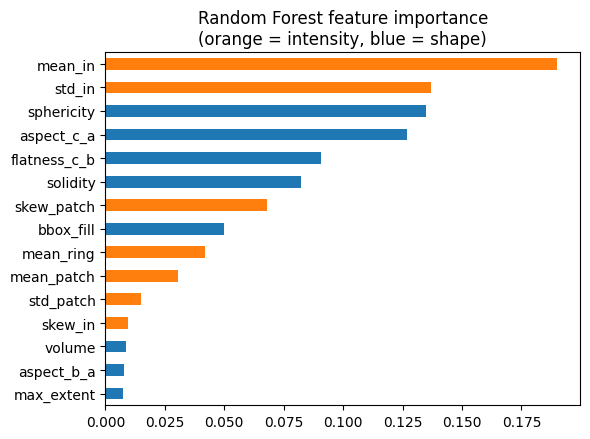

In [ ]:
ytr, yva, yte = DF['train'].label.values, DF['val'].label.values, DF['test'].label.values
mk_rf  = lambda **p: RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1, **p)
mk_svm = lambda **p: make_pipeline(StandardScaler(), SVC(kernel='rbf', **p))
rf_grid  = [dict(max_depth=d, min_samples_leaf=l) for d in (6, 12, None) for l in (1, 3)]
svm_grid = [dict(C=C, gamma=g) for C in (1, 10, 100) for g in ('scale', 0.01, 0.1)]
ALL, SHP = SHAPE_FEATS + INT_FEATS, SHAPE_FEATS

def tune(make, grid, cols, F):
    best = (-1, None, None)
    for params in grid:
        mdl = make(**params).fit(F['train'][cols], ytr)
        f1 = f1_score(yva, mdl.predict(F['val'][cols]), average='macro')
        if f1 > best[0]:
            best = (f1, params, mdl)
    return best

BASELINES = {}
specs = [('RF (shape+intensity)',   'rf_shape_intensity',  mk_rf,  rf_grid,  ALL, FEAT),
         ('SVM (shape+intensity)',  'svm_shape_intensity', mk_svm, svm_grid, ALL, FEAT),
         ('RF (shape only)',        'rf_shape_only',       mk_rf,  rf_grid,  SHP, FEAT),
         ('RF (thresholded mask)',  'rf_thresholded_mask', mk_rf,  rf_grid,  ALL, FEAT_T)]
for name, key, make, grid, cols, F in specs:
    f1, params, mdl = tune(make, grid, cols, F)
    BASELINES[name] = mdl
    print(f'{name:24s} best params {params} | validation macro-F1 = {f1:.4f}')
    pred = mdl.predict(F['test'][cols])
    pd.DataFrame(dict(patch_id=DF['test'].patch_id, y_true=yte, y_pred=pred)).to_csv(f'{RES_DIR}/preds_{key}_test.csv', index=False)

imp = pd.Series(BASELINES['RF (shape+intensity)'].feature_importances_, index=ALL).sort_values()
plt.figure(figsize=(6, 4.5))
imp.plot.barh(color=['tab:orange' if f in INT_FEATS else 'tab:blue' for f in imp.index])
plt.title('Random Forest feature importance\n(orange = intensity, blue = shape)'); plt.tight_layout()
plt.savefig(FIG_DIR + '/rf_feature_importance.png', dpi=150); plt.show()

=== TEST SET: all models (n=1125, 95% CIs by resampling parent volumes) ===
                        accuracy      acc 95% CI  macro-F1       F1 95% CI  recall pore  recall crack  recall inclusion
model                                                                                                                  
3D CNN (raw intensity)     0.990  [0.984, 0.996]     0.990  [0.984, 0.996]        0.995         0.992             0.984
3D CNN (shape-only)        0.815  [0.796, 0.838]     0.810  [0.789, 0.835]        0.883         1.000             0.563
RF (shape+intensity)       0.991  [0.986, 0.997]     0.991  [0.986, 0.997]        0.989         0.997             0.987
SVM (shape+intensity)      0.997  [0.994, 1.000]     0.997  [0.994, 1.000]        0.995         0.997             1.000
RF (shape only)            0.836  [0.812, 0.860]     0.834  [0.808, 0.858]        0.651         0.997             0.861
RF (thresholded mask)      0.988  [0.981, 0.996]     0.988  [0.981, 0.996]        0.

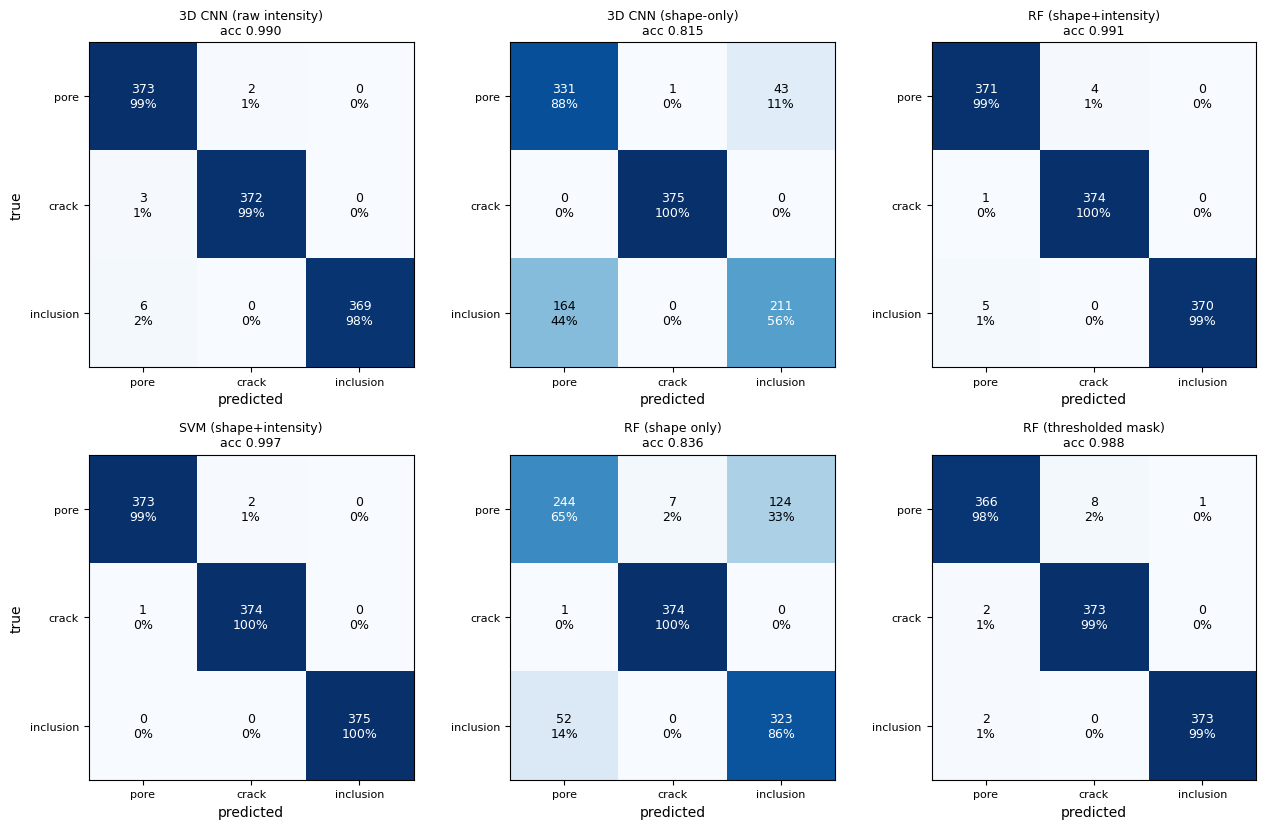

In [ ]:
dte = DF['test'].copy()
def get_pred(fname):
    p = pd.read_csv(f'{RES_DIR}/{fname}')
    assert (p.patch_id.values == dte.patch_id.values).all() and (p.y_true.values == dte.label.values).all()
    return p.y_pred.values

PRED = {'3D CNN (raw intensity)': get_pred('preds_cnn_raw_test.csv'),
        '3D CNN (shape-only)':    get_pred('preds_cnn_shape_only_test.csv'),
        'RF (shape+intensity)':   get_pred('preds_rf_shape_intensity_test.csv'),
        'SVM (shape+intensity)':  get_pred('preds_svm_shape_intensity_test.csv'),
        'RF (shape only)':        get_pred('preds_rf_shape_only_test.csv'),
        'RF (thresholded mask)':  get_pred('preds_rf_thresholded_mask_test.csv')}
y = dte.label.values
COL = {'3D CNN (raw intensity)': 'tab:blue', '3D CNN (shape-only)': 'tab:red', 'RF (shape+intensity)': 'tab:green',
       'SVM (shape+intensity)': 'tab:olive', 'RF (shape only)': 'tab:gray', 'RF (thresholded mask)': 'tab:purple'}

def cluster_ci(metric, p, B=500, seed=0):
    groups = {g: np.where(dte.parent_id.values == g)[0] for g in dte.parent_id.unique()}
    keys, rng, vals = np.array(list(groups)), np.random.default_rng(seed), []
    for _ in range(B):
        idx = np.concatenate([groups[g] for g in rng.choice(keys, len(keys))])
        vals.append(metric(y[idx], p[idx]))
    return np.percentile(vals, [2.5, 97.5])

macro = lambda a, b: f1_score(a, b, average='macro')
rows = []
for name, p in PRED.items():
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=[0, 1, 2], zero_division=0)
    ci_a, ci_f = cluster_ci(accuracy_score, p), cluster_ci(macro, p)
    rows.append({'model': name, 'accuracy': accuracy_score(y, p), 'acc 95% CI': f'[{ci_a[0]:.3f}, {ci_a[1]:.3f}]',
                 'macro-F1': macro(y, p), 'F1 95% CI': f'[{ci_f[0]:.3f}, {ci_f[1]:.3f}]',
                 **{f'recall {c}': r for c, r in zip(CLASS_NAMES, rc)}, **{f'precision {c}': q for c, q in zip(CLASS_NAMES, pr)}})
MAIN = pd.DataFrame(rows).set_index('model')
MAIN.round(4).to_csv(TAB_DIR + '/table_main_comparison.csv')
print('=== TEST SET: all models (n=%d, 95%% CIs by resampling parent volumes) ===' % len(y))
display_cols = ['accuracy', 'acc 95% CI', 'macro-F1', 'F1 95% CI', 'recall pore', 'recall crack', 'recall inclusion']
print(MAIN[display_cols].round(3).to_string())

for name in ['3D CNN (raw intensity)', '3D CNN (shape-only)']:
    print(f'\n{name}'); print(classification_report(y, PRED[name], target_names=CLASS_NAMES, digits=3))

def mcnemar(p1, p2):
    c1, c2 = p1 == y, p2 == y
    b, c = int((c1 & ~c2).sum()), int((~c1 & c2).sum())
    n = b + c
    chi = (abs(b - c) - 1) ** 2 / n if n else 0.0
    return dict(only_first_correct=b, only_second_correct=c, chi2=round(chi, 2),
                p_chi2=chi2_dist.sf(chi, 1), p_exact=binomtest(b, n, 0.5).pvalue if n else 1.0)
pairs = [('3D CNN (raw intensity)', '3D CNN (shape-only)'), ('3D CNN (raw intensity)', 'RF (shape+intensity)'),
         ('3D CNN (raw intensity)', 'SVM (shape+intensity)'), ('3D CNN (raw intensity)', 'RF (thresholded mask)'),
         ('RF (shape+intensity)', 'RF (shape only)')]
MC = pd.DataFrame([{'model 1': a, 'model 2': b, **mcnemar(PRED[a], PRED[b])} for a, b in pairs])
MC.to_csv(TAB_DIR + '/table_mcnemar.csv', index=False)
print("\n=== McNemar's test ===")
print(MC.to_string(index=False, float_format=lambda v: f'{v:.2e}' if v < 1e-3 else f'{v:.4f}'))

fig, axes = plt.subplots(2, 3, figsize=(13, 8.4)); axes = axes.ravel()
for ax, (name, p) in zip(axes, PRED.items()):
    cm = confusion_matrix(y, p, labels=[0, 1, 2]); cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{cm[i, j]}\n{cmn[i, j]*100:.0f}%', ha='center', va='center', color='white' if cmn[i, j] > .5 else 'black', fontsize=9)
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES, fontsize=8); ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES, fontsize=8)
    ax.set_title(f'{name}\nacc {accuracy_score(y, p):.3f}', fontsize=9); ax.set_xlabel('predicted')
[a.set_ylabel('true') for a in axes[::3]]; plt.tight_layout(); plt.savefig(FIG_DIR + '/confusion_all_models.png', dpi=150); plt.show()

=== Recall by attenuation-contrast stratum ===
                        subtle (n=54)  moderate (n=142)  obvious (n=179)  pore recall (n=375)  crack recall (n=375)
model                                                                                                              
3D CNN (raw intensity)          1.000             1.000            0.966                0.995                 0.992
3D CNN (shape-only)             0.481             0.535            0.609                0.883                 1.000
RF (shape+intensity)            1.000             1.000            0.972                0.989                 0.997
SVM (shape+intensity)           1.000             1.000            1.000                0.995                 0.997
RF (shape only)                 0.852             0.859            0.866                0.651                 0.997
RF (thresholded mask)           1.000             1.000            0.989                0.976                 0.995


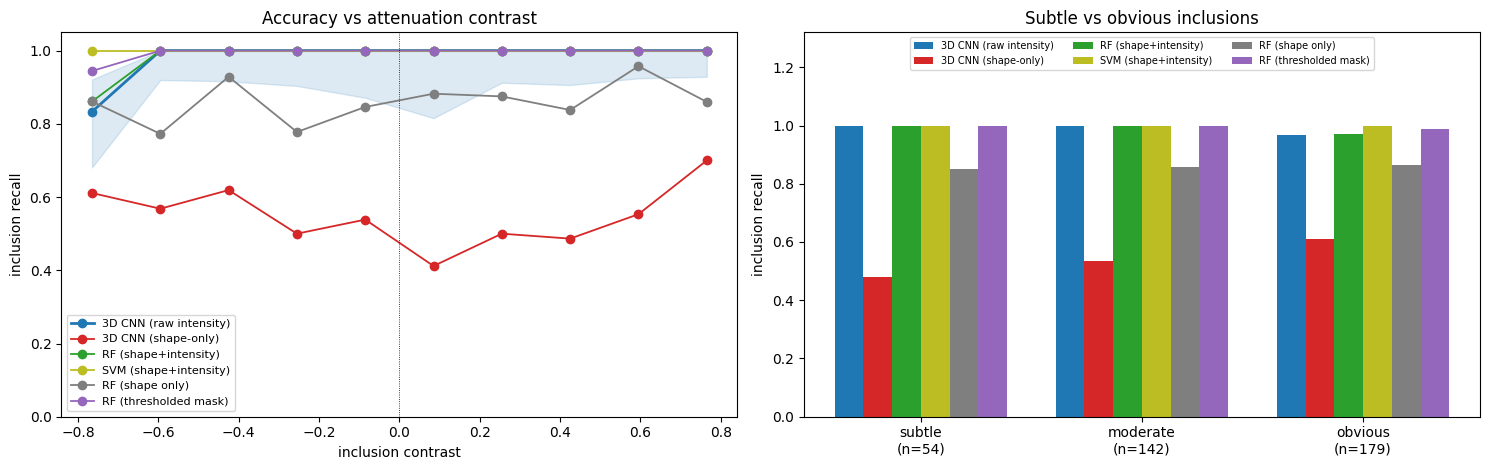

In [ ]:
def wilson(k, n):
    return binomtest(int(k), int(n)).proportion_ci(method='wilson') if n else None

inc = (dte.label == 2).values

bins = ['subtle', 'moderate', 'obvious']
rows = []
for name, p in PRED.items():
    r = {'model': name}
    for b in bins:
        m = (dte.contrast_bin == b).values
        r[f'{b} (n={m.sum()})'] = (p[m] == 2).mean()
    for c, cn in [(0, 'pore'), (1, 'crack')]:
        m = (dte.label == c).values
        r[f'{cn} recall (n={m.sum()})'] = (p[m] == c).mean()
    rows.append(r)
STRAT = pd.DataFrame(rows).set_index('model')
STRAT.round(3).to_csv(TAB_DIR + '/table_contrast_bins.csv')
print('=== Recall by attenuation-contrast stratum ===')
print(STRAT.round(3).to_string())

edges = np.round(np.linspace(-0.85, 0.85, 11), 3)
ctr = dte.contrast.values
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
mids = (edges[:-1] + edges[1:]) / 2
curve_rows = []
for name, p in PRED.items():
    rec, lo, hi, ns = [], [], [], []
    for a, b in zip(edges[:-1], edges[1:]):
        m = inc & (ctr >= a) & (ctr < b + (1e-9 if b == edges[-1] else 0))
        k, n = (p[m] == 2).sum(), m.sum()
        ci = wilson(k, n)
        rec.append(k / n if n else np.nan); lo.append(ci.low if n else np.nan); hi.append(ci.high if n else np.nan); ns.append(n)
        curve_rows.append(dict(model=name, bin=f'{a:+.2f}..{b:+.2f}', n=n, inclusion_recall=k / n if n else np.nan))
    ax[0].plot(mids, rec, 'o-', color=COL[name], label=name, lw=2 if 'raw' in name else 1.3)
    if 'raw' in name:
        ax[0].fill_between(mids, lo, hi, color=COL[name], alpha=0.15)
ax[0].axvline(0, color='k', lw=0.6, ls=':'); ax[0].set_ylim(0, 1.05)
ax[0].set_xlabel('inclusion contrast'); ax[0].set_ylabel('inclusion recall')
ax[0].set_title('Accuracy vs attenuation contrast'); ax[0].legend(fontsize=8, loc='lower left')
pd.DataFrame(curve_rows).to_csv(TAB_DIR + '/table_recall_vs_signed_contrast.csv', index=False)

x = np.arange(3); w = 0.13
for i, (name, p) in enumerate(PRED.items()):
    vals = [(p[(dte.contrast_bin == b).values] == 2).mean() for b in bins]
    ax[1].bar(x + (i - (len(PRED) - 1) / 2) * w, vals, w, label=name, color=COL[name])
ax[1].set_xticks(x); ax[1].set_xticklabels([f'{b}\n(n={(dte.contrast_bin == b).sum()})' for b in bins])
ax[1].set_ylim(0, 1.32); ax[1].set_ylabel('inclusion recall'); ax[1].set_title('Subtle vs obvious inclusions'); ax[1].legend(fontsize=7, ncol=3, loc='upper center')
plt.tight_layout(); plt.savefig(FIG_DIR + '/accuracy_vs_contrast.png', dpi=150); plt.show()

=== Accuracy by noise tier (test set) ===
tier                    high (SNR 40)  medium (SNR 20)  low (SNR 10)
model                                                               
3D CNN (raw intensity)          0.987            1.000         0.984
3D CNN (shape-only)             0.816            0.804         0.825
RF (shape only)                 0.816            0.878         0.815
RF (shape+intensity)            0.987            1.000         0.987
RF (thresholded mask)           0.987            1.000         0.978
SVM (shape+intensity)           1.000            1.000         0.992

Raw CNN per-class recall by noise tier:
           tier  recall pore  recall crack  recall inclusion
  high (SNR 40)        1.000         0.992             0.968
medium (SNR 20)        1.000         1.000             1.000
   low (SNR 10)        0.984         0.984             0.984

Raw CNN recall of SUBTLE inclusions by noise tier:
  high   (SNR 40): 1.000  (n=19)
  medium (SNR 20): 1.000  (n=12)
  l

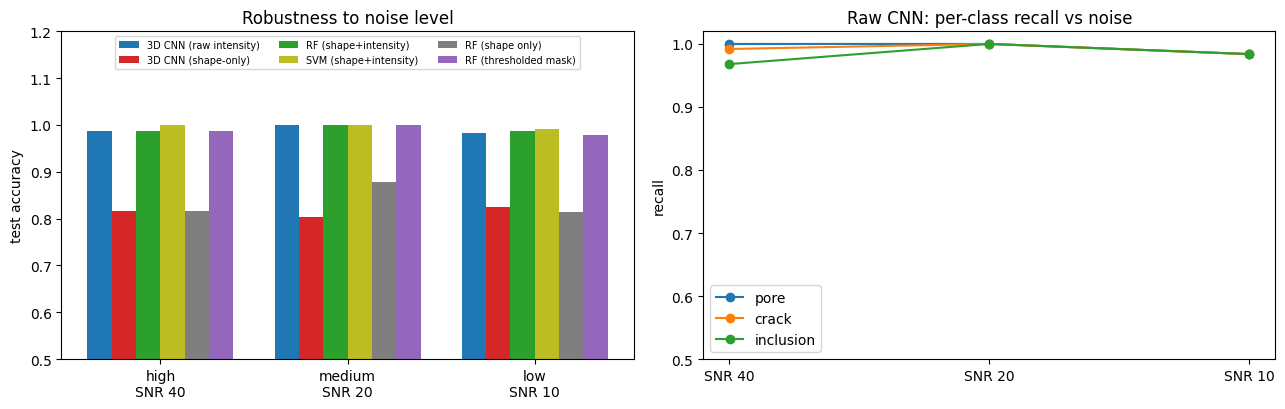

In [ ]:
tiers = ['high', 'medium', 'low']
snr_lab = {'high': 'SNR 40', 'medium': 'SNR 20', 'low': 'SNR 10'}
rows = []
for name, p in PRED.items():
    for t in tiers:
        m = (dte.snr_tier == t).values
        rows.append({'model': name, 'tier': f'{t} ({snr_lab[t]})', 'n': int(m.sum()),
                     'accuracy': accuracy_score(y[m], p[m]), 'macro-F1': macro(y[m], p[m])})
NOISE = pd.DataFrame(rows)
NOISE.round(4).to_csv(TAB_DIR + '/table_noise_tiers.csv', index=False)
print('=== Accuracy by noise tier (test set) ===')
print(NOISE.pivot(index='model', columns='tier', values='accuracy').reindex(columns=[f'{t} ({snr_lab[t]})' for t in tiers]).round(3).to_string())

raw = PRED['3D CNN (raw intensity)']
rec_rows = []
for t in tiers:
    m = (dte.snr_tier == t).values
    rec_rows.append({'tier': f'{t} ({snr_lab[t]})', **{f'recall {cn}': (raw[m & (y == c)] == c).mean() for c, cn in enumerate(CLASS_NAMES)}})
print('\nRaw CNN per-class recall by noise tier:'); print(pd.DataFrame(rec_rows).round(3).to_string(index=False))

print('\nRaw CNN recall of SUBTLE inclusions by noise tier:')
for t in tiers:
    m = ((dte.snr_tier == t) & (dte.contrast_bin == 'subtle')).values
    print(f'  {t:6s} ({snr_lab[t]}): {(raw[m] == 2).mean():.3f}  (n={m.sum()})')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
x, w = np.arange(3), 0.13
for i, name in enumerate(PRED):
    acc = [NOISE[(NOISE.model == name) & NOISE.tier.str.startswith(t)].accuracy.values[0] for t in tiers]
    ax[0].bar(x + (i - (len(PRED) - 1) / 2) * w, acc, w, label=name, color=COL[name])
ax[0].set_xticks(x); ax[0].set_xticklabels([f'{t}\n{snr_lab[t]}' for t in tiers]); ax[0].set_ylim(0.5, 1.2)
ax[0].set_ylabel('test accuracy'); ax[0].set_title('Robustness to noise level'); ax[0].legend(fontsize=7, ncol=3, loc='upper center')
for c, cn in enumerate(CLASS_NAMES):
    ax[1].plot(range(3), [(raw[(dte.snr_tier == t).values & (y == c)] == c).mean() for t in tiers], 'o-', label=cn)
ax[1].set_xticks(range(3)); ax[1].set_xticklabels([snr_lab[t] for t in tiers]); ax[1].set_ylim(0.5, 1.02)
ax[1].set_ylabel('recall'); ax[1].set_title('Raw CNN: per-class recall vs noise'); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR + '/robustness_noise.png', dpi=150); plt.show()

=== Pore <-> inclusion confusion rates (test set) ===
model                         3D CNN (raw intensity) 3D CNN (shape-only) RF (shape+intensity) SVM (shape+intensity) RF (shape only) RF (thresholded mask)
pore -> inclusion                              0.000               0.115                0.000                 0.000           0.331                 0.003
incl->pore [-0.85,-0.70) n=36                  0.167               0.389                0.139                 0.000           0.139                 0.056
incl->pore [-0.70,-0.55) n=36                  0.000               0.417                0.000                 0.000           0.194                 0.000
incl->pore [-0.55,-0.40) n=39                  0.000               0.436                0.000                 0.000           0.154                 0.000
incl->pore [-0.40,-0.20) n=42                  0.000               0.429                0.000                 0.000           0.143                 0.000
incl->pore [-0.20,+0.0

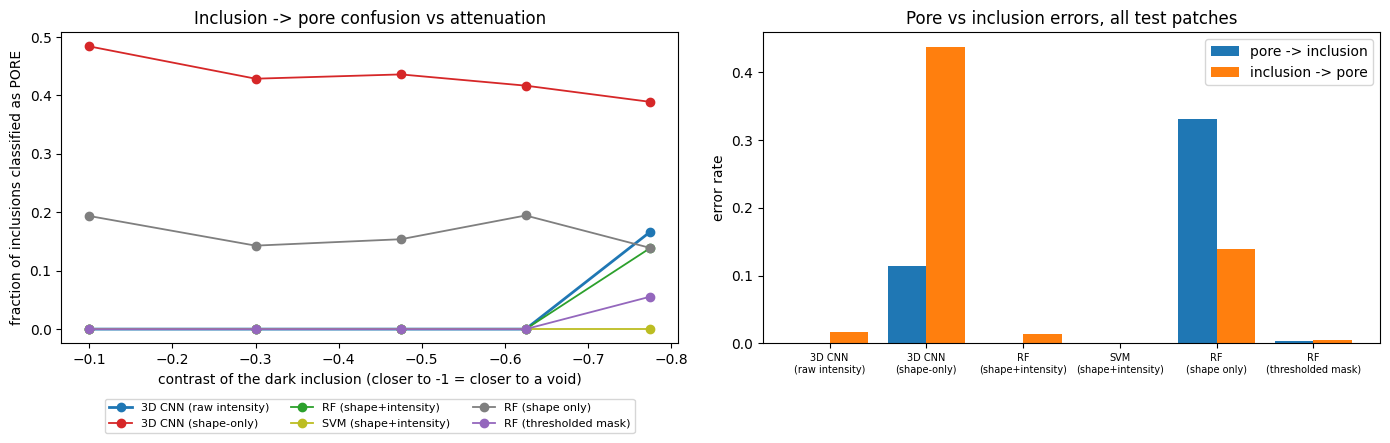

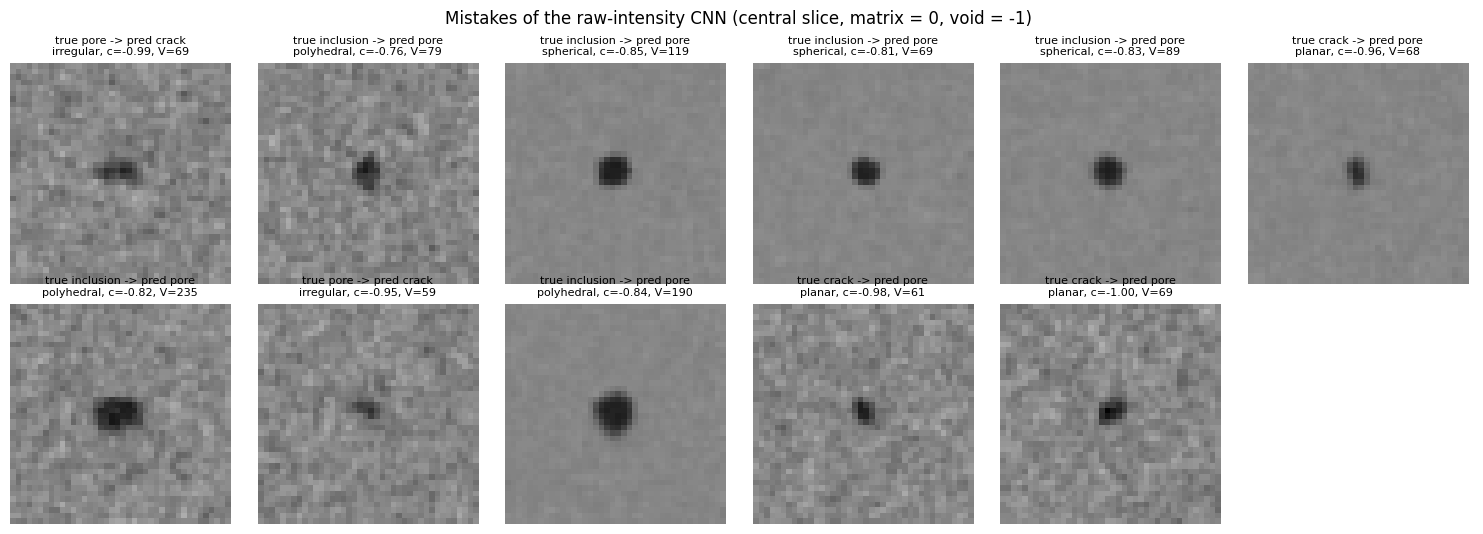

In [ ]:
pore = (dte.label == 0).values
dark_edges = [(-0.85, -0.70), (-0.70, -0.55), (-0.55, -0.40), (-0.40, -0.20), (-0.20, 0.0)]
rows = []
for name, p in PRED.items():
    r = {'model': name, 'pore -> inclusion': f'{(p[pore] == 2).mean():.3f}'}
    for a, b in dark_edges:
        m = inc & (ctr >= a) & (ctr < b)
        r[f'incl->pore [{a:+.2f},{b:+.2f}) n={m.sum()}'] = f'{(p[m] == 0).mean():.3f}'
    bright = inc & (ctr > 0)
    r[f'bright incl->pore n={bright.sum()}'] = f'{(p[bright] == 0).mean():.3f}'
    rows.append(r)
PI = pd.DataFrame(rows).set_index('model')
PI.to_csv(TAB_DIR + '/table_pore_vs_inclusion.csv')
print('=== Pore <-> inclusion confusion rates (test set) ===')
print(PI.T.to_string())

err = dte[(raw != y)].copy()
err['predicted'] = [CLASS_NAMES[i] for i in raw[raw != y]]
err = err[['patch_id', 'class_name', 'predicted', 'subtype', 'contrast', 'actual_volume', 'snr_tier', 'parent_id']]
err.to_csv(TAB_DIR + '/table_raw_cnn_errors.csv', index=False)
print(f'\n=== All {len(err)} test errors of the raw-intensity CNN ===')
print(err.round(3).to_string(index=False))

sub = dte.groupby(['class_name', 'subtype']).apply(lambda d: pd.Series({n: (PRED[n][d.index] == d.label.values).mean() for n in PRED}))
sub.insert(0, 'n', dte.groupby(['class_name', 'subtype']).size())
sub.round(3).to_csv(TAB_DIR + '/table_recall_by_subtype.csv')
print('\n=== Recall per defect sub-type (test set) ==='); print(sub.round(3).to_string())

dark = inc & (ctr <= -0.4)
q = pd.qcut(dte.actual_volume[dark], 3, labels=['small', 'medium', 'large'])
print('\nDark inclusions (contrast <= -0.4): fraction called "pore" by defect size')
print(pd.DataFrame({n: pd.Series(PRED[n][dark.nonzero()[0]] == 0, index=q.index).groupby(q).mean() for n in list(PRED)[:2]}).round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
mids = [(a + b) / 2 for a, b in dark_edges]
for name, p in PRED.items():
    ax[0].plot(mids, [(p[inc & (ctr >= a) & (ctr < b)] == 0).mean() for a, b in dark_edges], 'o-', color=COL[name], label=name, lw=2 if 'raw' in name else 1.3)
ax[0].set_xlabel('contrast of the dark inclusion (closer to -1 = closer to a void)'); ax[0].set_ylabel('fraction of inclusions classified as PORE')
ax[0].set_title('Inclusion -> pore confusion vs attenuation'); ax[0].legend(fontsize=8, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.16)); ax[0].invert_xaxis()
names = list(PRED)
ax[1].bar(np.arange(len(names)) - 0.2, [(PRED[n][pore] == 2).mean() for n in names], 0.4, label='pore -> inclusion')
ax[1].bar(np.arange(len(names)) + 0.2, [(PRED[n][inc] == 0).mean() for n in names], 0.4, label='inclusion -> pore')
ax[1].set_xticks(range(len(names))); ax[1].set_xticklabels([n.replace(' (', '\n(') for n in names], fontsize=7)
ax[1].set_ylabel('error rate'); ax[1].set_title('Pore vs inclusion errors, all test patches'); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR + '/pore_vs_inclusion.png', dpi=150); plt.show()

Xt = np.load(f'{DATA_DIR}/patches_test.npy', mmap_mode='r')
idx = list(err.index)[:12]
if idx:
    fig, axes = plt.subplots(2, 6, figsize=(15, 5.4)); axes = axes.ravel()
    for a in axes: a.axis('off')
    for a, i in zip(axes, idx):
        a.imshow(((Xt[i].astype(np.float32) - dte.bg_level[i]) / dte.bg_level[i])[20], cmap='gray', vmin=-1.1, vmax=1.0)
        a.set_title(f'true {dte.class_name[i]} -> pred {CLASS_NAMES[raw[i]]}\n{dte.subtype[i]}, c={dte.contrast[i]:+.2f}, V={dte.actual_volume[i]}', fontsize=8)
    plt.suptitle('Mistakes of the raw-intensity CNN (central slice, matrix = 0, void = -1)'); plt.tight_layout()
    plt.savefig(FIG_DIR + '/raw_cnn_errors_gallery.png', dpi=150); plt.show()

In [ ]:
a_raw, a_shp = accuracy_score(y, PRED['3D CNN (raw intensity)']), accuracy_score(y, PRED['3D CNN (shape-only)'])
mc = MC.iloc[0]
print('KEY NUMBERS (copy into the report)')
print('-' * 70)
print(f'Raw-intensity CNN        : accuracy {a_raw:.3f}, macro-F1 {macro(y, PRED["3D CNN (raw intensity)"]):.3f}')
print(f'Shape-only CNN (ablation): accuracy {a_shp:.3f}, macro-F1 {macro(y, PRED["3D CNN (shape-only)"]):.3f}')
print(f'Contribution of attenuation information: {100*(a_raw-a_shp):.1f} accuracy points')
print(f"McNemar raw vs shape-only: {mc.only_first_correct} patches only raw correct, {mc.only_second_correct} only shape-only correct, exact p = {mc.p_exact:.2e}")
for n in ['RF (shape+intensity)', 'SVM (shape+intensity)', 'RF (shape only)']:
    print(f'{n:24s}: accuracy {accuracy_score(y, PRED[n]):.3f}')
print('Subtle-inclusion recall (raw CNN / shape-only CNN / RF): %.3f / %.3f / %.3f' % tuple(
    (PRED[n][(dte.contrast_bin == "subtle").values] == 2).mean() for n in ['3D CNN (raw intensity)', '3D CNN (shape-only)', 'RF (shape+intensity)']))
print('\nAll tables  ->', TAB_DIR)
print('All figures ->', FIG_DIR)
print(sorted(os.listdir(TAB_DIR))); print(sorted(os.listdir(FIG_DIR)))

KEY NUMBERS (copy into the report)
----------------------------------------------------------------------
Raw-intensity CNN        : accuracy 0.990, macro-F1 0.990
Shape-only CNN (ablation): accuracy 0.815, macro-F1 0.810
Contribution of attenuation information: 17.5 accuracy points
McNemar raw vs shape-only: 205 patches only raw correct, 8 only shape-only correct, exact p = 1.45e-50
RF (shape+intensity)    : accuracy 0.991
SVM (shape+intensity)   : accuracy 0.997
RF (shape only)         : accuracy 0.836
Subtle-inclusion recall (raw CNN / shape-only CNN / RF): 1.000 / 0.481 / 1.000

All tables  -> /content/drive/MyDrive/defect_project/results/tables
All figures -> /content/drive/MyDrive/defect_project/results/figures
['table_contrast_bins.csv', 'table_main_comparison.csv', 'table_mcnemar.csv', 'table_noise_tiers.csv', 'table_pore_vs_inclusion.csv', 'table_raw_cnn_errors.csv', 'table_recall_by_subtype.csv', 'table_recall_vs_signed_contrast.csv']
['accuracy_vs_contrast.png', 'confusion_a

In [ ]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
warnings.filterwarnings('ignore')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/defect_project'
except ImportError:
    BASE = './defect_project'
DATA_DIR, MODEL_DIR, RES_DIR = BASE + '/data', BASE + '/models', BASE + '/results'
FIG_DIR = RES_DIR + '/figures'
for d in (MODEL_DIR, RES_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

SEED, CROP, BATCH = 42, 32, 64
MAX_EPOCHS, PATIENCE, LR = 60, 12, 1e-3
FORCE_RETRAIN = False
CLASS_NAMES = ['pore', 'crack', 'inclusion']

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device, '|', torch.cuda.get_device_name(0) if device == 'cuda' else 'NO GPU!')
if device != 'cuda':
    print('>>> Turn on the GPU: Runtime -> Change runtime type -> T4 GPU, then re-run from Cell 1.')
torch.manual_seed(SEED); np.random.seed(SEED)
torch.backends.cudnn.benchmark = True
print('Data folder  :', DATA_DIR)
print('Results folder:', RES_DIR)

Mounted at /content/drive
Device: cuda | Tesla T4
Data folder  : /content/drive/MyDrive/defect_project/data
Results folder: /content/drive/MyDrive/defect_project/results


In [ ]:
def load_split(s):
    X = np.load(f'{DATA_DIR}/patches_{s}.npy')
    M = np.load(f'{DATA_DIR}/masks_{s}.npy')
    df = pd.read_csv(f'{DATA_DIR}/index_{s}.csv')
    assert len(X) == len(M) == len(df)
    return X, M, df

def normalise(X, bg, chunk=500):
    out = np.empty(X.shape, np.float16)
    for k in range(0, len(X), chunk):
        b = bg[k:k + chunk].astype(np.float32)[:, None, None, None]
        out[k:k + chunk] = ((X[k:k + chunk].astype(np.float32) - b) / b).astype(np.float16)
    return out

RAW = {}
for s in ['train', 'val', 'test']:
    X, M, df = load_split(s)
    RAW[s] = dict(x=normalise(X, df.bg_level.values), m=M, df=df)
    del X
    print(f'{s:5s}: patches {RAW[s]["x"].shape}, labels {np.bincount(df.label)}')

train: patches (5250, 40, 40, 40), labels [1750 1750 1750]
val  : patches (1125, 40, 40, 40), labels [375 375 375]
test : patches (1125, 40, 40, 40), labels [375 375 375]


In [ ]:
DATA = {}
for s in RAW:
    DATA[s] = dict(x_raw=torch.from_numpy(RAW[s]['x']).to(device),
                   x_mask=torch.from_numpy(RAW[s]['m']).to(device),
                   y=torch.tensor(RAW[s]['df'].label.values, dtype=torch.long, device=device),
                   df=RAW[s]['df'])
if device == 'cuda':
    print(f'GPU memory used: {torch.cuda.memory_allocated()/1e9:.2f} GB')

GPU memory used: 1.44 GB


In [ ]:
def conv_block(cin, cout):
    return nn.Sequential(
        nn.Conv3d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm3d(cout), nn.ReLU(inplace=True),
        nn.Conv3d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm3d(cout), nn.ReLU(inplace=True),
        nn.MaxPool3d(2))

class DefectCNN3D(nn.Module):
    def __init__(self, n_classes=3, ch=(16, 32, 64, 128), drop=0.3):
        super().__init__()
        c = (1,) + tuple(ch)
        self.features = nn.Sequential(*[conv_block(c[i], c[i + 1]) for i in range(4)])
        self.head = nn.Sequential(nn.Linear(ch[-1], 32), nn.ReLU(inplace=True), nn.Dropout(drop), nn.Linear(32, n_classes))

    def forward(self, x):
        x = self.features(x)
        x = x.mean(dim=(2, 3, 4))
        return self.head(x)

_m = DefectCNN3D()
n_params = sum(p.numel() for p in _m.parameters())
print(f'DefectCNN3D parameters: {n_params:,}  (brief: ~0.5-1 M)')
del _m

DefectCNN3D parameters: 883,443  (brief: ~0.5-1 M)


In [ ]:
def center_crop(x):
    o = (x.shape[-1] - CROP) // 2
    return x[:, o:o + CROP, o:o + CROP, o:o + CROP].unsqueeze(1).float()

def augment(x, intensity=False):
    B, S = x.shape[0], x.shape[-1]
    out = torch.empty((B, 1, CROP, CROP, CROP), device=x.device, dtype=torch.float32)
    offs = torch.randint(0, S - CROP + 1, (B, 3)).tolist()
    for i in range(B):
        a, b, c = offs[i]
        v = x[i, a:a + CROP, b:b + CROP, c:c + CROP].float()
        v = v.permute(*torch.randperm(3).tolist())
        flips = [d for d in range(3) if torch.rand(1).item() < 0.5]
        if flips:
            v = torch.flip(v, flips)
        out[i, 0] = v
    if intensity:
        shp = (B, 1, 1, 1, 1)
        gain = torch.empty(shp, device=x.device).uniform_(0.95, 1.05)
        offset = torch.empty(shp, device=x.device).uniform_(-0.02, 0.02)
        extra = torch.empty(shp, device=x.device).uniform_(0.0, 0.02)
        out = out * gain + offset + torch.randn_like(out) * extra
    return out

def make_scaler():
    try:
        return torch.amp.GradScaler('cuda')
    except Exception:
        return torch.cuda.amp.GradScaler()

def train_one_epoch(model, opt, scaler, X, y, intensity):
    model.train()
    n = X.shape[0]
    perm = torch.randperm(n, device=X.device)
    loss_sum = torch.zeros((), device=X.device); correct = torch.zeros((), device=X.device); seen = 0
    for k in range(0, n - BATCH + 1, BATCH):
        idx = perm[k:k + BATCH]
        xb, yb = augment(X[idx], intensity), y[idx]
        opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda', dtype=torch.float16):
            logits = model(xb)
            loss = F.cross_entropy(logits, yb)
        scaler.scale(loss).backward()
        scaler.step(opt); scaler.update()
        loss_sum += loss.detach() * len(idx)
        correct += (logits.argmax(1) == yb).sum()
        seen += len(idx)
    return loss_sum.item() / seen, correct.item() / seen

@torch.no_grad()
def predict(model, X, bs=256):
    model.eval()
    out = []
    for k in range(0, X.shape[0], bs):
        with torch.autocast('cuda', dtype=torch.float16):
            out.append(model(center_crop(X[k:k + bs])).float())
    return torch.cat(out)

def train_model(name, Xtr, ytr, Xva, yva, intensity_aug, max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=SEED):
    torch.manual_seed(seed); np.random.seed(seed)
    model = DefectCNN3D().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', factor=0.5, patience=4)
    scaler = make_scaler()
    last, best = f'{MODEL_DIR}/{name}_last.pt', f'{MODEL_DIR}/{name}_best.pt'
    hist, start, best_f1, bad = [], 0, -1.0, 0

    if os.path.exists(last) and not FORCE_RETRAIN:
        ck = torch.load(last, map_location=device, weights_only=False)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
        hist, start, best_f1, bad = ck['hist'], ck['epoch'], ck['best_f1'], ck['bad']
        print(f'[{name}] resuming from epoch {start} (best val macro-F1 so far {best_f1:.4f})')

    yva_np = yva.cpu().numpy()
    finished = (bad >= patience) or (start >= max_epochs)

    for ep in range(start, 0 if finished else max_epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, opt, scaler, Xtr, ytr, intensity_aug)
        logits = predict(model, Xva)
        val_loss = F.cross_entropy(logits, yva).item()
        pred = logits.argmax(1).cpu().numpy()
        f1, acc = f1_score(yva_np, pred, average='macro'), accuracy_score(yva_np, pred)
        sched.step(f1)

        if f1 > best_f1 + 1e-4:
            best_f1, bad = f1, 0
            torch.save(model.state_dict(), best)
        else:
            bad += 1

        hist.append(dict(epoch=ep + 1, train_loss=tr_loss, train_acc=tr_acc, val_loss=val_loss, val_acc=acc,
                         val_macro_f1=f1, lr=opt.param_groups[0]['lr'], seconds=time.time() - t0))
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        hist=hist, epoch=ep + 1, best_f1=best_f1, bad=bad), last)
        print(f'[{name}] ep {ep+1:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {val_loss:.3f} acc {acc:.3f} '
              f'macro-F1 {f1:.3f} | best {best_f1:.3f} | lr {opt.param_groups[0]["lr"]:.0e} | {time.time()-t0:.0f}s')

        if bad >= patience:
            print(f'[{name}] early stopping (no val macro-F1 gain for {patience} epochs)')
            break

    pd.DataFrame(hist).to_csv(f'{RES_DIR}/history_{name}.csv', index=False)
    model.load_state_dict(torch.load(best, map_location=device, weights_only=False))
    return model, pd.DataFrame(hist)

print('Training functions ready')

Training functions ready


In [ ]:
SEEDS = [1, 2, 3, 4]

def save_preds_named(name, model, key):
    for s in ['val', 'test']:
        probs = torch.softmax(predict(model, DATA[s][key]), 1).cpu().numpy()
        d = DATA[s]['df']
        pd.DataFrame(dict(patch_id=d.patch_id, y_true=d.label.values, y_pred=probs.argmax(1),
                          p_pore=probs[:, 0], p_crack=probs[:, 1], p_inclusion=probs[:, 2])).to_csv(f'{RES_DIR}/preds_{name}_{s}.csv', index=False)

t_all = time.time()
for sd in SEEDS:
    for tag, key, aug in [('cnn_raw', 'x_raw', True), ('cnn_shape_only', 'x_mask', False)]:
        name = f'{tag}_s{sd}'
        if os.path.exists(f'{RES_DIR}/preds_{name}_test.csv') and not FORCE_RETRAIN:
            print(f'--- {name}: already finished, skipping'); continue
        print(f'\n=== training {name} ===')
        model, hist = train_model(name, DATA['train'][key], DATA['train']['y'], DATA['val'][key], DATA['val']['y'], aug, seed=sd)
        save_preds_named(name, model, key)
        print(f'{name}: best val macro-F1 {hist.val_macro_f1.max():.4f}')
        del model; torch.cuda.empty_cache()
print(f'\nAll seeds done in {(time.time()-t_all)/60:.1f} min')

--- cnn_raw_s1: already finished, skipping
--- cnn_shape_only_s1: already finished, skipping
--- cnn_raw_s2: already finished, skipping
--- cnn_shape_only_s2: already finished, skipping
--- cnn_raw_s3: already finished, skipping
--- cnn_shape_only_s3: already finished, skipping
--- cnn_raw_s4: already finished, skipping
--- cnn_shape_only_s4: already finished, skipping

All seeds done in 0.0 min


=== Per-seed test results ===
 seed  raw_acc  raw_f1  shape_acc  shape_f1  raw_incl_recall  shape_incl_recall  raw_errors  drop_points
   42   0.9902  0.9902     0.8151    0.8102           0.9840             0.5627          11      17.5111
    1   0.9920  0.9920     0.8107    0.8088           0.9947             0.8133           9      18.1333
    2   0.9884  0.9884     0.8142    0.8132           0.9893             0.6507          13      17.4222
    3   0.9876  0.9876     0.8427    0.8423           0.9867             0.8107          14      14.4889
    4   0.9911  0.9911     0.8373    0.8364           0.9893             0.6827          10      15.3778

=== mean +/- std over 5 seeds ===
raw-intensity CNN : accuracy 0.990 +/- 0.002 | macro-F1 0.990 +/- 0.002
shape-only CNN    : accuracy 0.824 +/- 0.015 | macro-F1 0.822 +/- 0.016
drop              : 16.6 +/- 1.6 accuracy points

Headline run (seed 42): drop = 17.5 points, scan-level bootstrap 95% CI [15.1, 19.6]


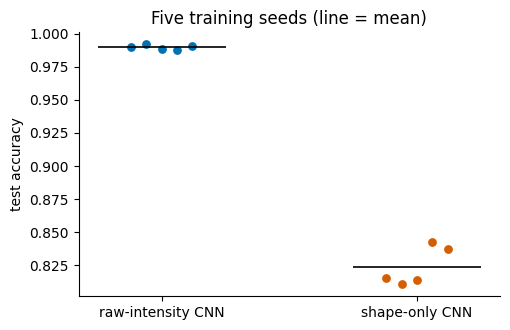


COPY THIS INTO THE PREPRINT (Section 5.1, replace the yellow SEEDS text):
Over five independent training runs (seeds 42, 1, 2, 3, 4) the raw-intensity CNN reached a mean ± std accuracy of 0.990 ± 0.002 and the shape-only CNN 0.824 ± 0.015, a drop of 16.6 ± 1.6 points; the 17.5-point drop of the headline run has a scan-level bootstrap 95 % CI of 15.1 to 19.6 points.


In [ ]:
from scipy.stats import binomtest
SEED_LIST = [42, 1, 2, 3, 4]
dte = pd.read_csv(f'{DATA_DIR}/index_test.csv')

def get_pred(tag, sd):
    f = f'{RES_DIR}/preds_{tag}_test.csv' if sd == 42 else f'{RES_DIR}/preds_{tag}_s{sd}_test.csv'
    p = pd.read_csv(f)
    assert (p.patch_id.values == dte.patch_id.values).all()
    return p.y_pred.values

y = dte.label.values
rows = []
for sd in SEED_LIST:
    pr, ps = get_pred('cnn_raw', sd), get_pred('cnn_shape_only', sd)
    rows.append(dict(seed=sd, raw_acc=accuracy_score(y, pr), raw_f1=f1_score(y, pr, average='macro'),
                     shape_acc=accuracy_score(y, ps), shape_f1=f1_score(y, ps, average='macro'),
                     raw_incl_recall=(pr[y == 2] == 2).mean(), shape_incl_recall=(ps[y == 2] == 2).mean(),
                     raw_errors=int((pr != y).sum())))

SEEDS_DF = pd.DataFrame(rows); SEEDS_DF['drop_points'] = 100 * (SEEDS_DF.raw_acc - SEEDS_DF.shape_acc)
SEEDS_DF.round(4).to_csv(f'{RES_DIR}/table_seed_repeats.csv', index=False)
print('=== Per-seed test results ===')
print(SEEDS_DF.round(4).to_string(index=False))

ms = lambda c: (SEEDS_DF[c].mean(), SEEDS_DF[c].std(ddof=1))
(ra, rs), (sa, ss), (dm, dsd) = ms('raw_acc'), ms('shape_acc'), ms('drop_points')
(rf1, rf1s), (sf1, sf1s) = ms('raw_f1'), ms('shape_f1')
print('\n=== mean +/- std over 5 seeds ===')
print(f'raw-intensity CNN : accuracy {ra:.3f} +/- {rs:.3f} | macro-F1 {rf1:.3f} +/- {rf1s:.3f}')
print(f'shape-only CNN    : accuracy {sa:.3f} +/- {ss:.3f} | macro-F1 {sf1:.3f} +/- {sf1s:.3f}')
print(f'drop              : {dm:.1f} +/- {dsd:.1f} accuracy points')

pr, ps = get_pred('cnn_raw', 42), get_pred('cnn_shape_only', 42)
groups = {g: np.where(dte.parent_id.values == g)[0] for g in dte.parent_id.unique()}
keys, rng, diffs = np.array(list(groups)), np.random.default_rng(0), []
for _ in range(2000):
    idx = np.concatenate([groups[g] for g in rng.choice(keys, len(keys))])
    diffs.append(100 * ((pr[idx] == y[idx]).mean() - (ps[idx] == y[idx]).mean()))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f'\nHeadline run (seed 42): drop = {100*(accuracy_score(y, pr)-accuracy_score(y, ps)):.1f} points, scan-level bootstrap 95% CI [{lo:.1f}, {hi:.1f}]')

fig, ax = plt.subplots(figsize=(5.2, 3.4))
for k, (c, lab, col) in enumerate([('raw_acc', 'raw-intensity CNN', '#0072B2'), ('shape_acc', 'shape-only CNN', '#D55E00')]):
    ax.scatter(np.full(len(SEEDS_DF), k) + np.linspace(-0.12, 0.12, len(SEEDS_DF)), SEEDS_DF[c], color=col, s=28, zorder=3)
    ax.hlines(SEEDS_DF[c].mean(), k - 0.25, k + 0.25, color='k', lw=1.2, zorder=4)
ax.set_xticks([0, 1]); ax.set_xticklabels(['raw-intensity CNN', 'shape-only CNN']); ax.set_ylabel('test accuracy'); ax.set_title('Five training seeds (line = mean)')
ax.spines[['top', 'right']].set_visible(False); plt.tight_layout(); plt.savefig(f'{FIG_DIR}/seed_repeats.png', dpi=300); plt.show()

print('\n' + '=' * 78 + '\nCOPY THIS INTO THE PREPRINT (Section 5.1, replace the yellow SEEDS text):\n' + '=' * 78)
print(f'Over five independent training runs (seeds 42, 1, 2, 3, 4) the raw-intensity CNN reached a mean ± std accuracy of '
      f'{ra:.3f} ± {rs:.3f} and the shape-only CNN {sa:.3f} ± {ss:.3f}, a drop of {dm:.1f} ± {dsd:.1f} points; the '
      f'{100*(accuracy_score(y, pr)-accuracy_score(y, ps)):.1f}-point drop of the headline run has a scan-level bootstrap 95 % CI of {lo:.1f} to {hi:.1f} points.')